# 02 · Analisi del test finale held-out

## Music Discovery CMAB — Last.fm 1K

Analisi delle **cinque configurazioni congelate sulla validation**. Il notebook verifica manifesto, configurazione, aggregati e checkpoint, poi confronta il test con i run selezionati a N=100. Non effettua selezione o tuning sul test.

Le metriche mantengono il cutoff esplicito `@5`, `@10` o `@20`. Nei CSV, `catalog_coverage` e `artist_coverage` senza suffisso sono alias di @20. I JSONL grandi vengono verificati con hashing a blocchi; non sono caricati in memoria.

### Riproducibilità della sezione qualitativa

I grafici qualitativi si rigenerano dalla cache versionata in `notebooks/data/qualitative_examples.json`; non richiedono risultati sperimentali locali né il dataset. La riproducibilità del notebook completo richiede invece gli aggregati e i checkpoint ufficiali, esclusi dal repository. I prerequisiti dei tre notebook sono descritti in `notebooks/README.md`.


In [1]:
from __future__ import annotations
import hashlib,json,math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

def root_from(path=None):
    p=(path or Path.cwd()).resolve()
    for q in (p,*p.parents):
        if (q/'experiments/configs/final_test.json').is_file(): return q
    raise FileNotFoundError('Repository root not found')
def sha256(path,chunk=8*1024*1024):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        while b:=f.read(chunk): h.update(b)
    return h.hexdigest()
ROOT=root_from(); MANIFEST=ROOT/'experiments/configs/final_selection_manifest.json'
CONFIG=ROOT/'experiments/configs/final_test.json'
TEST=ROOT/'experiments/results/test/044f9269d4e3-5b076e7a'
VAL=ROOT/'experiments/results/validation/ea8616724509-5b076e7a'
CP=ROOT/'experiments/results/checkpoints/final-test-044f9269d4e3-5b076e7a1cb3'
TEST_CSV=TEST/'runs.csv'; TEST_JSONL=TEST/'runs.jsonl'; VAL_CSV=VAL/'runs.csv'
EXPECTED_CSV_SHA='7089ff59433a1725254da3f5cdd4157fafbe8a11d0140f108cabf18385a27831'
EXPECTED_JSONL_SHA='c660298186085c6d16f9499c60aa2ab46b4206ea42c14684896c1b724ddc81f8'
EXPECTED_CONFIG_HASH='044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b'
EXPECTED_DATASET_HASH='5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a'
EXPECTED_COMMIT='4cd1fe0dc907ac3620a6f0b08653623fb30608c7'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':180,'axes.titlesize':12,'axes.labelsize':10,'legend.frameon':False,'font.size':9})
pd.set_option('display.max_columns',40); pd.set_option('display.width',220)
manifest=json.loads(MANIFEST.read_text(encoding='utf-8')); config=json.loads(CONFIG.read_text(encoding='utf-8'))
print(f'Repository: {ROOT}; held-out JSONL: {TEST_JSONL.stat().st_size/1e9:.2f} GB')

Repository: C:\Users\dales\OneDrive\Desktop\PROGETTO SII\music-discovery-CMAB; held-out JSONL: 1.34 GB


## 1. Verifica di integrità e provenienza

Gli hash dei due aggregati sono verificati in streaming. Ogni checkpoint deve avere marker `completed`, identità compatibile e payload dettagliato con checksum valido. Il manifesto conferma che parametri e run ID sono stati congelati sulla validation e che il test non è stato usato per selezionare.

In [2]:
unsigned=dict(manifest); manifest_sha=unsigned.pop('manifest_sha256')
computed_manifest_sha=hashlib.sha256(json.dumps(unsigned,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode()).hexdigest()
config_hash=hashlib.sha256(json.dumps(config,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode()).hexdigest()
raw_config_sha=sha256(CONFIG)
assert raw_config_sha==manifest['final_test_config_file_sha256']
assert computed_manifest_sha==manifest_sha
assert config_hash==EXPECTED_CONFIG_HASH==manifest['final_test_config_hash']
assert manifest['dataset_content_hash']==EXPECTED_DATASET_HASH
assert manifest['selection_status']=='frozen_before_held_out_test' and not manifest['selection_rule']['test_metrics_used_for_selection']
assert manifest['primary_candidate_pool_depth']==100
csv_sha=sha256(TEST_CSV); jsonl_sha=sha256(TEST_JSONL); val_csv_sha=sha256(VAL_CSV)
assert csv_sha==EXPECTED_CSV_SHA and jsonl_sha==EXPECTED_JSONL_SHA
assert val_csv_sha==manifest['validation_results']['aggregate_csv_sha256']
validation=pd.read_csv(VAL_CSV); test=pd.read_csv(TEST_CSV)
assert len(test)==5 and test.run_id.is_unique and set(test.completion_status)=={'completed'}
assert set(test.evaluation_phase)=={'test'} and set(test.candidate_pool_depth)=={100}
assert set(test.dataset_content_hash)=={EXPECTED_DATASET_HASH} and set(test.configuration_hash)=={EXPECTED_CONFIG_HASH}
assert set(test.git_commit)=={EXPECTED_COMMIT} and set(test.experiment_code_digest)=={manifest['final_test_runner_source_digest']}
assert set(test.test_start)=={'2009-03-01'} and set(test.test_end)=={'2009-05-05'}
assert set(test.reward_horizon_days)=={7} and set(test.seed)=={42} and set(test.random_seed)=={42}
assert (test.n_users==562).all() and (test.n_decisions==82905).all() and (test.skipped_decisions==0).all()
assert test.candidate_pool_digest.nunique()==test.eligible_user_hash.nunique()==test.scaler_digest.nunique()==1
assert test.scaler_digest.iloc[0]=='903fbb2a19d1b6e30608e02943cd5e54e2fa90f87ae514b04f5d19532b8a10b9'
params=manifest['final_parameters']; assert set(test.policy)==set(params)
for r in test.to_dict('records'):
    assert json.loads(r['policy_parameters'])==params[r['policy']]
    assert params[r['policy']]==manifest['final_parameters'][r['policy']]
    assert r['K_values']=='5,10,20'
VERIFY_DETAIL_CHECKSUMS=False  # Set True to additionally rehash each per-policy JSONL checkpoint.
markers=sorted(CP.glob('*.checkpoint.json')); assert len(markers)==5
by_id={}
for p in markers:
    m=json.loads(p.read_text(encoding='utf-8')); i=m['identity']; rid=i['run_id']
    assert m['completion_status']=='completed' and rid==p.name.removesuffix('.checkpoint.json') and rid not in by_id
    assert i['evaluation_phase']=='test' and i['dataset_content_hash']==EXPECTED_DATASET_HASH
    assert i['configuration_hash']==EXPECTED_CONFIG_HASH and i['git_commit']==EXPECTED_COMMIT
    assert i['experiment_code_digest']==manifest['final_test_runner_source_digest']
    detail=CP/m['result_filename']; assert detail.is_file() and isinstance(m.get('result_sha256'),str) and len(m['result_sha256'])==64
    if VERIFY_DETAIL_CHECKSUMS: assert sha256(detail)==m['result_sha256']
    by_id[rid]=m
assert set(by_id)==set(test.run_id)
for r in test.to_dict('records'):
    m=by_id[r['run_id']]; i=m['identity']
    assert i['policy']==r['policy'] and i['candidate_pool_depth']==100
    assert i['random_seed']==r['random_seed'] and i['experiment_code_digest']==r['experiment_code_digest']
    assert i['policy_parameters']==json.loads(r['policy_parameters'])
    assert i['scaler_digest']==r['scaler_digest'] and i['candidate_pool_digest']==r['candidate_pool_digest']
    for k in ['ndcg@10','average_reward']:
        assert math.isclose(float(m['summary'][k]),float(r[k]),rel_tol=0,abs_tol=1e-14)
for a,b in [('catalog_coverage','catalog_coverage@20'),('artist_coverage','artist_coverage@20')]:
    assert np.allclose(test[a],test[b],rtol=0,atol=1e-14)
print('Manifest SHA-256:',manifest_sha)
print('Final config hash:',config_hash,' | raw config SHA-256:',raw_config_sha)
print('Dataset:',EXPECTED_DATASET_HASH,' | commit:',EXPECTED_COMMIT)
print('Test CSV SHA-256:',csv_sha,' | Test JSONL SHA-256:',jsonl_sha)
print(f'PASS · {len(test)}/5 unique completed rows and {len(by_id)}/5 verified checkpoints')

Manifest SHA-256: 93086553c6929c3a0c571a8c1c004744178b701e91b1c88a5038d536c4a21fdd
Final config hash: 044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b  | raw config SHA-256: 76e59cefb025579b84f75f4e691387059e76b11b4a08b1c778109c1dabaad40c
Dataset: 5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a  | commit: 4cd1fe0dc907ac3620a6f0b08653623fb30608c7
Test CSV SHA-256: 7089ff59433a1725254da3f5cdd4157fafbe8a11d0140f108cabf18385a27831  | Test JSONL SHA-256: c660298186085c6d16f9499c60aa2ab46b4206ea42c14684896c1b724ddc81f8
PASS · 5/5 unique completed rows and 5/5 verified checkpoints


## 2. Risultati held-out

La tabella completa contiene metriche di ranking, novelty, diversità e coverage a K=5, 10 e 20; è ordinata per NDCG@10. Average Reward è una misura della sola azione Top-1 e quindi non ha cutoff K.

In [3]:
LABEL={'random':'Random','popularity':'Global Popularity','greedy':'Personalized Greedy','epsilon_greedy':'ε-Greedy','linucb':'LinUCB'}
test['policy_label']=test.policy.map(LABEL)
test['parameter']=test.apply(lambda r:f"α={r.alpha:g}" if r.policy=='linucb' else f"ε={r.epsilon:g}" if r.policy=='epsilon_greedy' else f"seed={int(r.random_seed)}" if r.policy=='random' else '—',axis=1)
metrics=['ndcg@5','ndcg@10','ndcg@20','average_reward']+[f'{m}@{k}' for m in ['precision','recall','track_novelty','artist_novelty','artist_ild','catalog_coverage','artist_coverage'] for k in (5,10,20)]
table=test[['policy_label','parameter','candidate_pool_depth','run_id']+metrics].sort_values('ndcg@10',ascending=False).reset_index(drop=True)
display(table.style.format({c:'{:.6f}' for c in metrics}).set_caption('Test held-out · cinque policy congelate · ordinate per NDCG@10'))

,policy_label,parameter,candidate_pool_depth,run_id,ndcg@5,ndcg@10,ndcg@20,average_reward,precision@5,precision@10,precision@20,recall@5,recall@10,recall@20,track_novelty@5,track_novelty@10,track_novelty@20,artist_novelty@5,artist_novelty@10,artist_novelty@20,artist_ild@5,artist_ild@10,artist_ild@20,catalog_coverage@5,catalog_coverage@10,catalog_coverage@20,artist_coverage@5,artist_coverage@10,artist_coverage@20
0,Personalized Greedy,—,100,56d64c6681486489,0.299744,0.258795,0.226655,0.973338,0.403090,0.364422,0.312121,0.036630,0.053806,0.076603,0.428003,0.448135,0.484342,0.000000,0.000000,0.000000,0.703799,0.752957,0.802236,0.195390,0.283425,0.410757,0.199426,0.285578,0.415444
1,LinUCB,α=2,100,0178a03a59b83f79,0.299467,0.257741,0.221357,0.913353,0.367270,0.320681,0.262718,0.038040,0.054112,0.075783,0.542255,0.556484,0.583223,0.070830,0.101535,0.157702,0.797706,0.832490,0.874082,0.292426,0.385071,0.508233,0.314295,0.416401,0.548819
2,ε-Greedy,ε=0.05,100,27e68f15f1b587f3,0.288001,0.248893,0.218264,0.929997,0.386336,0.349606,0.299679,0.034984,0.051404,0.073656,0.450852,0.469995,0.504320,0.022893,0.023193,0.023286,0.718243,0.764725,0.811658,0.428321,0.545774,0.681668,0.474474,0.596362,0.730057
3,Random,seed=42,100,e9dd950ba6698a6e,0.059115,0.058348,0.057709,0.083866,0.059437,0.058273,0.056549,0.006425,0.012488,0.023137,0.881678,0.881662,0.881825,0.462700,0.465040,0.469460,0.993376,0.993400,0.993287,0.842371,0.911745,0.954116,0.888960,0.940970,0.969049
4,Global Popularity,—,100,43b15fb56d1fa75d,0.056281,0.036927,0.041048,0.266868,0.164711,0.164711,0.136021,0.003878,0.003878,0.008740,0.642070,0.650198,0.669677,0.220333,0.220333,0.238681,0.000000,0.000000,0.338792,0.002195,0.004391,0.009879,0.000319,0.000319,0.001276


## 3. Confronto validation vs test

Per ciascuna policy si abbina il run held-out al run ID selezionato nel manifesto a N=100. Delta = `test − validation`; delta relativo = `100 × delta / |validation|`. Sono differenze descrittive tra periodi, non intervalli di confidenza né prove di significatività.

Ranking validation: LinUCB > Personalized Greedy > ε-Greedy > Random > Global Popularity
Ranking test:       Personalized Greedy > LinUCB > ε-Greedy > Random > Global Popularity


,policy,run_id_validation,run_id_test,ndcg@10_validation,ndcg@10_test,ndcg@10_delta,ndcg@10_relative_pct,average_reward_validation,average_reward_test,average_reward_delta,average_reward_relative_pct
2,Personalized Greedy,4ee1c7cd8ab862b1,56d64c6681486489,0.276427,0.258795,-0.017632,-6.378384,1.060560,0.973338,-0.087223,-8.224202
4,LinUCB,f699daa9d589645c,0178a03a59b83f79,0.285640,0.257741,-0.027899,-9.767222,1.003704,0.913353,-0.090351,-9.001716
3,ε-Greedy,93648fba05cb426d,27e68f15f1b587f3,0.265987,0.248893,-0.017094,-6.426764,1.012495,0.929997,-0.082498,-8.148033
0,Random,68ee5a6012e54aef,e9dd950ba6698a6e,0.066118,0.058348,-0.007770,-11.751864,0.097295,0.083866,-0.013430,-13.802986
1,Global Popularity,d1b463f44b968420,43b15fb56d1fa75d,0.041145,0.036927,-0.004218,-10.252397,0.308597,0.266868,-0.041730,-13.522342


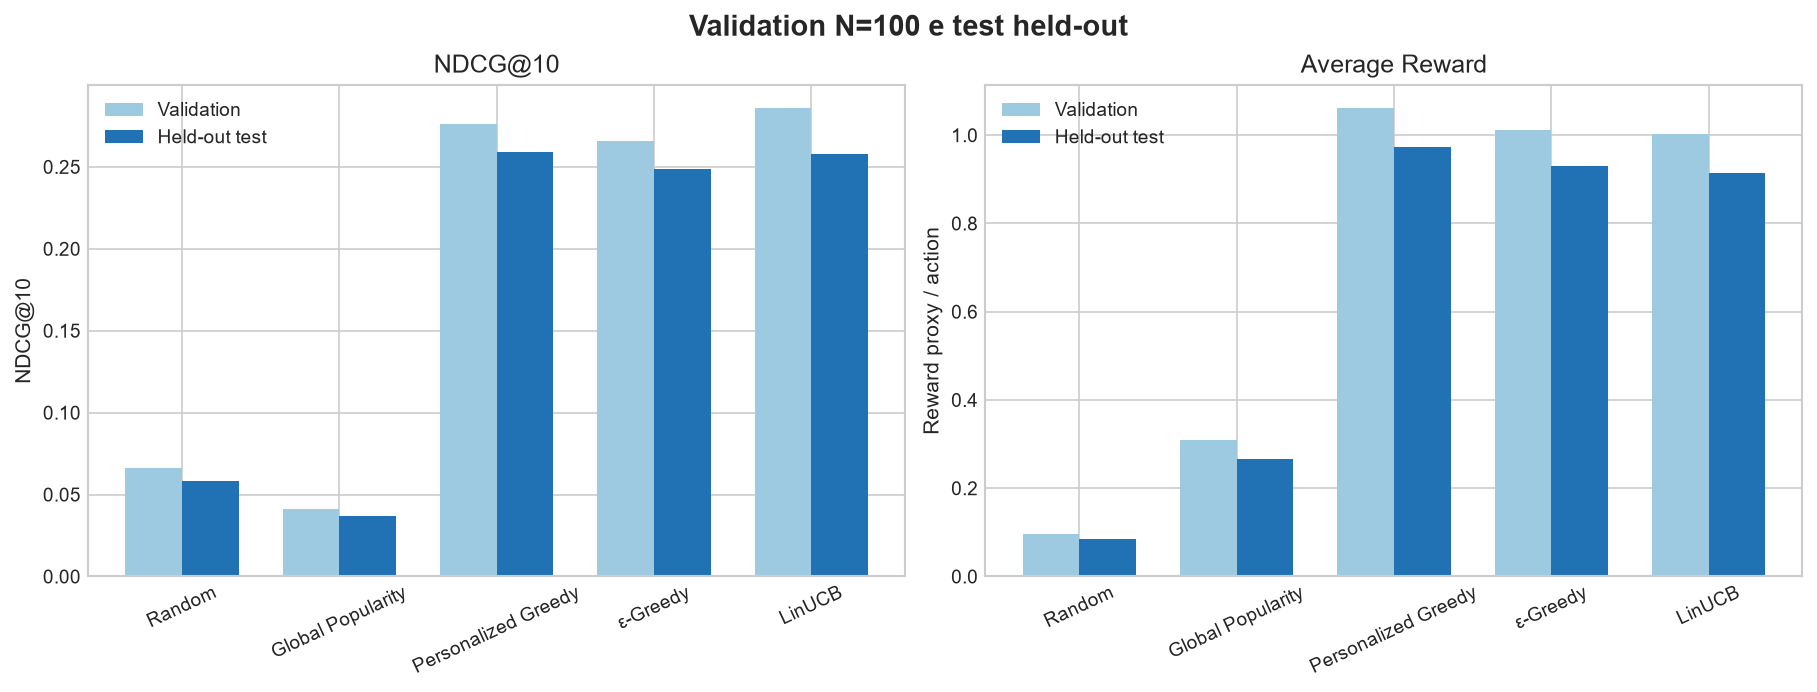

In [4]:
selected=[]
for p,item in manifest['selected_validation_runs'].items():
    g=validation[validation.run_id==item['run_id']]; assert len(g)==1 and g.iloc[0].policy==p and g.iloc[0].candidate_pool_depth==100
    assert json.loads(g.iloc[0].policy_parameters)==item['parameters']
    for metric in ['ndcg@10','average_reward']:
        assert math.isclose(float(g.iloc[0][metric]),float(manifest['validation_scores_at_n100'][p][metric]),rel_tol=0,abs_tol=1e-14)
    assert json.loads(test.loc[test.policy==p,'policy_parameters'].iloc[0])==manifest['final_parameters'][p]
    selected.append(g.iloc[0])
selected=pd.DataFrame(selected)
comp=test.merge(selected,on='policy',suffixes=('_test','_validation'),validate='one_to_one')
for m in ['ndcg@10','average_reward']:
    comp[f'{m}_delta']=comp[f'{m}_test']-comp[f'{m}_validation']
    comp[f'{m}_relative_pct']=100*comp[f'{m}_delta']/comp[f'{m}_validation'].abs().replace(0,np.nan)
rank_v=comp.sort_values('ndcg@10_validation',ascending=False).policy.tolist()
rank_t=comp.sort_values('ndcg@10_test',ascending=False).policy.tolist()
delta_table=comp[['policy','run_id_validation','run_id_test','ndcg@10_validation','ndcg@10_test','ndcg@10_delta','ndcg@10_relative_pct','average_reward_validation','average_reward_test','average_reward_delta','average_reward_relative_pct']].copy()
delta_table['policy']=delta_table.policy.map(LABEL)
display(delta_table.sort_values('ndcg@10_test',ascending=False).style.format({c:'{:.6f}' for c in delta_table.select_dtypes('number').columns}).set_caption('Differenze test − validation'))
print('Ranking validation:', ' > '.join(LABEL[p] for p in rank_v))
print('Ranking test:      ', ' > '.join(LABEL[p] for p in rank_t))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True); x=np.arange(len(comp)); w=.36
for ax,m,title,ylabel in [(axes[0],'ndcg@10','NDCG@10','NDCG@10'),(axes[1],'average_reward','Average Reward','Reward proxy / action')]:
    ax.bar(x-w/2,comp[f'{m}_validation'],w,label='Validation',color='#9ecae1')
    ax.bar(x+w/2,comp[f'{m}_test'],w,label='Held-out test',color='#2171b5')
    ax.set(title=title,ylabel=ylabel,xticks=x,xticklabels=[LABEL[p] for p in comp.policy]); ax.tick_params(axis='x',rotation=25); ax.legend()
fig.suptitle('Validation N=100 e test held-out',fontsize=14,fontweight='bold'); plt.show()

## 4. Trade-off accuratezza e scoperta

Ogni punto è una policy con lo stesso candidate-pool depth N=100. La posizione orizzontale rappresenta NDCG@10; gli assi verticali mostrano track novelty, artist novelty e artist ILD @10. I valori sono descrittivi: novelty e diversità più alte non implicano maggiore utilità per l'utente.

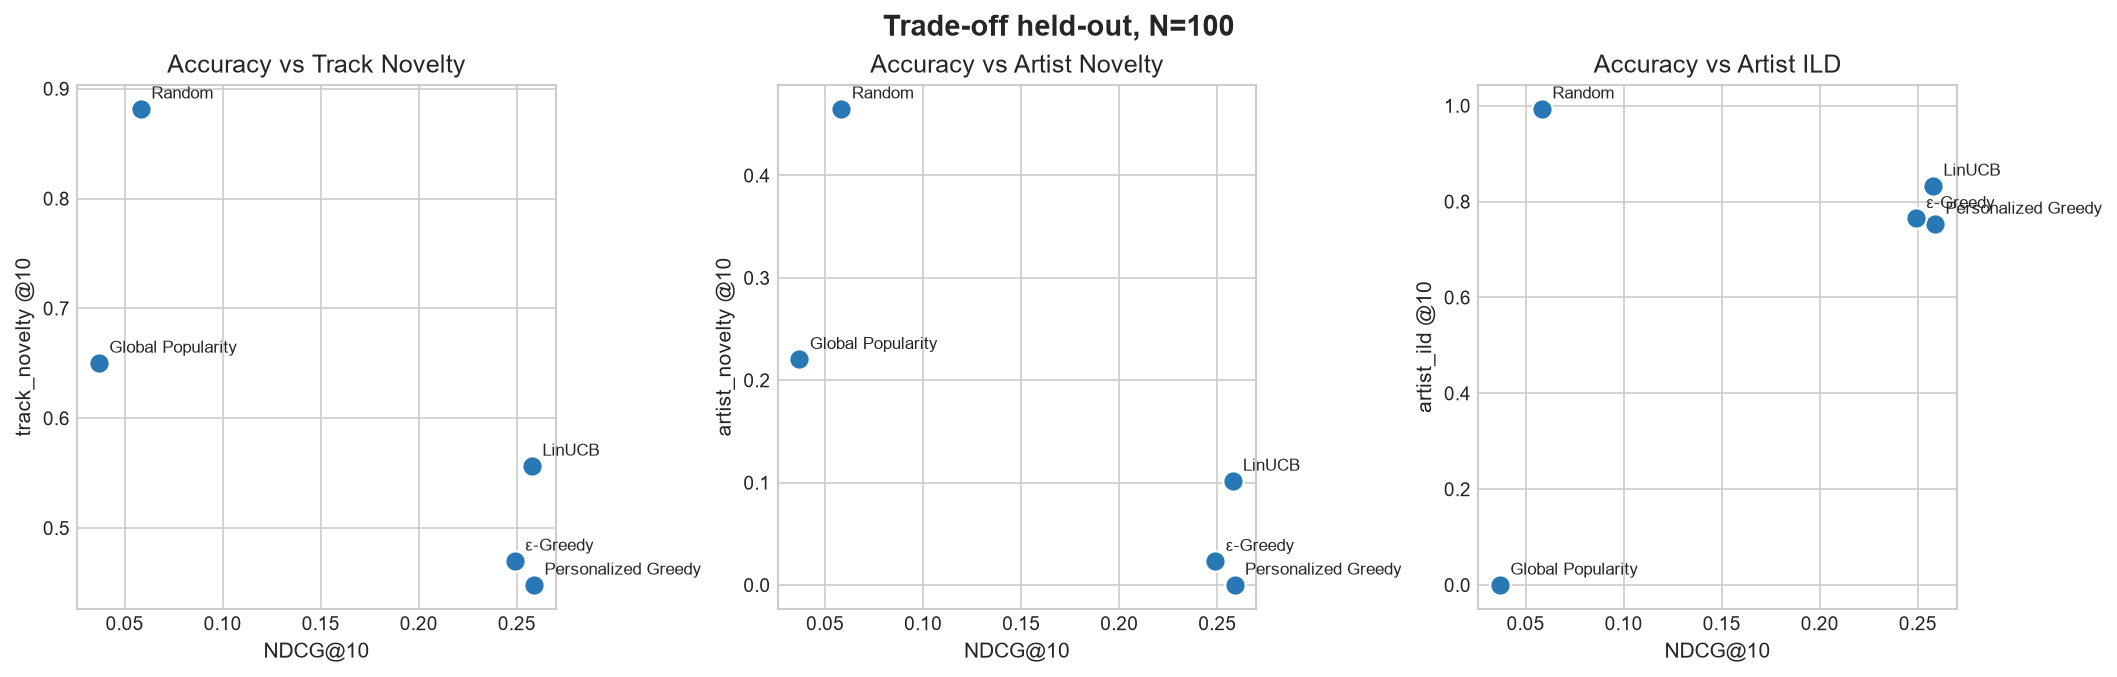

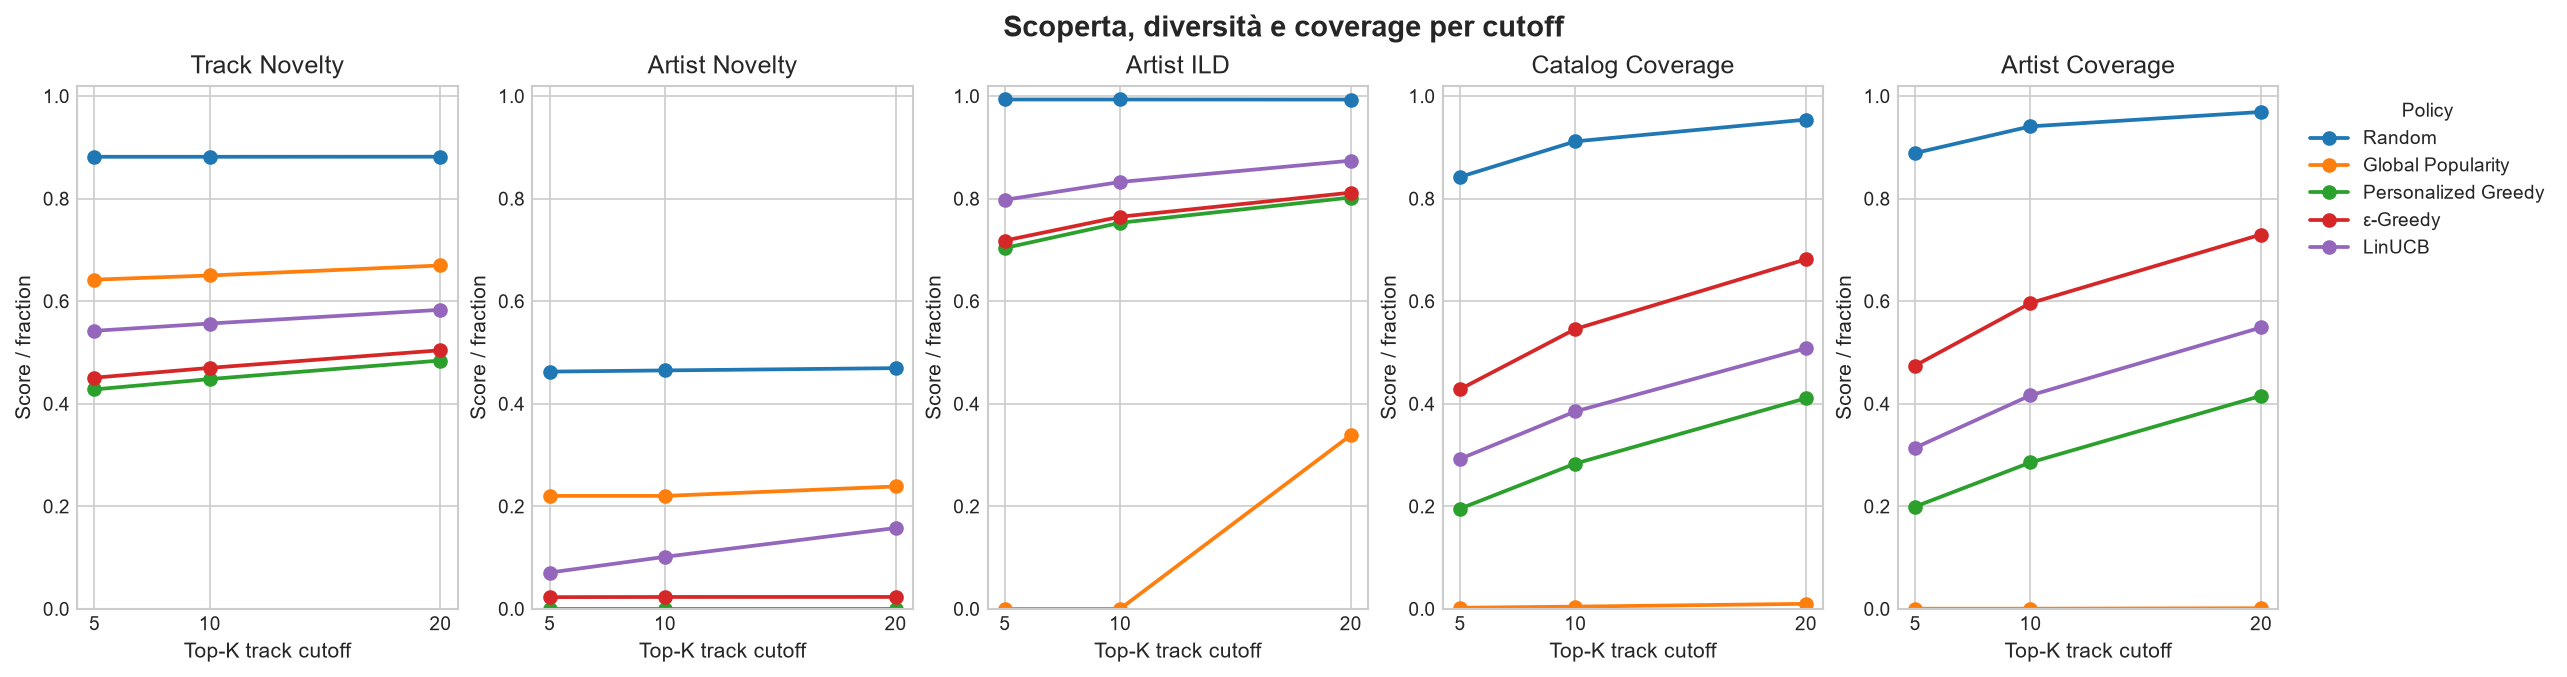

In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,4.4),constrained_layout=True)
for ax,y,title in [(axes[0],'track_novelty@10','Accuracy vs Track Novelty'),(axes[1],'artist_novelty@10','Accuracy vs Artist Novelty'),(axes[2],'artist_ild@10','Accuracy vs Artist ILD')]:
    ax.scatter(test['ndcg@10'],test[y],s=95,c='#2878B5',edgecolor='white',linewidth=1)
    for _,r in test.iterrows(): ax.annotate(r.policy_label,(r['ndcg@10'],r[y]),xytext=(5,5),textcoords='offset points',fontsize=8)
    ax.set(title=title,xlabel='NDCG@10',ylabel=y.replace('@10',' @10'))
fig.suptitle('Trade-off held-out, N=100',fontsize=14,fontweight='bold'); plt.show()

fig,axes=plt.subplots(1,5,figsize=(17,4.4),sharex=True,constrained_layout=True)
for ax,prefix,title in zip(axes,['track_novelty','artist_novelty','artist_ild','catalog_coverage','artist_coverage'],['Track Novelty','Artist Novelty','Artist ILD','Catalog Coverage','Artist Coverage']):
    for _,r in test.iterrows(): ax.plot([5,10,20],[r[f'{prefix}@{k}'] for k in (5,10,20)],marker='o',lw=1.8,label=r.policy_label)
    ax.set(title=title,xlabel='Top-K track cutoff',ylabel='Score / fraction',xticks=[5,10,20],ylim=(0,1.02))
axes[-1].legend(title='Policy',bbox_to_anchor=(1.04,1),loc='upper left')
fig.suptitle('Scoperta, diversità e coverage per cutoff',fontsize=14,fontweight='bold'); plt.show()

## 5. LinUCB rispetto a Personalized Greedy ed ε-Greedy

Il confronto riporta differenze puntuali per NDCG@10, Average Reward, novelty, ILD e coverage @10. Delta positivo significa che LinUCB ha un valore maggiore; per il confronto con Greedy la variazione percentuale di Artist Novelty non è definita perché la baseline vale zero.

In [6]:
lin=test[test.policy=='linucb'].iloc[0]; baselines=test[test.policy.isin(['greedy','epsilon_greedy'])]
cols=['ndcg@10','average_reward','track_novelty@10','artist_novelty@10','artist_ild@10','catalog_coverage@10','artist_coverage@10']
rows=[]
for _,b in baselines.iterrows():
    row={'Comparison':f"LinUCB − {LABEL[b.policy]}"}
    for m in cols:
        d=float(lin[m]-b[m]); row[f'Δ {m}']=d; row[f'Δ% {m}']=100*d/abs(float(b[m])) if b[m] else np.nan
    rows.append(row)
lin_compare=pd.DataFrame(rows)
display(lin_compare.style.format({c:'{:+.6f}' for c in lin_compare.select_dtypes('number').columns}).set_caption('LinUCB α=2.0 meno la baseline, metriche held-out @10'))

,Comparison,Δ ndcg@10,Δ% ndcg@10,Δ average_reward,Δ% average_reward,Δ track_novelty@10,Δ% track_novelty@10,Δ artist_novelty@10,Δ% artist_novelty@10,Δ artist_ild@10,Δ% artist_ild@10,Δ catalog_coverage@10,Δ% catalog_coverage@10,Δ artist_coverage@10,Δ% artist_coverage@10
0,LinUCB − Personalized Greedy,-0.001055,-0.407481,-0.059984,-6.162724,+0.108348,+24.177623,+0.101535,+nan,+0.079533,+10.562794,+0.101647,+35.863672,+0.130823,+45.810056
1,LinUCB − ε-Greedy,+0.008848,+3.554824,-0.016644,-1.789633,+0.086488,+18.401978,+0.078342,+337.783848,+0.067766,+8.861442,-0.160703,-29.444891,-0.179962,-30.176565


## 6. Esempi qualitativi delle raccomandazioni

Questa sezione confronta cinque decision point reali del test (U01–U05) per Personalized Greedy, ε-Greedy (ε=0.05) e LinUCB (α=2.0). Le liste, i nomi di brani e artisti, i flag di novelty artista e i dati di reward sono caricati dalla cache qualitativa verificata e versionata nel repository. La cache conserva la provenienza degli artefatti ufficiali; gli identificativi sorgente sono pseudonimi del dataset e nel notebook gli esempi sono mostrati con alias.

I grafici mostrano le Top-10 track, l'overlap degli item/artisti e la novelty a livello di artista, calcolata su `artist_key` distinti usando i flag pre-decisione verificati. La track novelty aggregata è disponibile nei risultati ufficiali, ma la storia esatta degli `item_key` per questi cinque utenti e timestamp non è persistita: la track novelty per esempio non viene ricostruita né sostituita con un proxy.

Il reward Top-1 è il proxy offline artist-level definito dal protocollo, calcolato sugli ascolti futuri dell'artista nella finestra `(t, t+7 giorni]`. Non dimostra che la track raccomandata sia stata esposta, ascoltata o causata dalla raccomandazione. I casi sono esempi descrittivi e non supportano generalizzazioni sulle policy.


In [7]:
from pathlib import Path
import csv
import hashlib
import json
import math
import re

import pandas as pd

START = Path.cwd().resolve()
ROOT = next(
    (candidate for candidate in (START, *START.parents)
     if (candidate / "notebooks" / "data" / "qualitative_examples.json").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Avvia questa sezione da una directory dentro il repository Music Discovery CMAB.")
CACHE_PATH = ROOT / "notebooks" / "data" / "qualitative_examples.json"
CHECKSUM_PATH = ROOT / "notebooks" / "data" / "qualitative_examples.json.sha256"
EXPECTED_CACHE_SHA256 = "ed582fc9a26189785bf440be58b0a4ee9a419c77e20c8131bf0ea6ed7840341b"
_cache_bytes = CACHE_PATH.read_bytes()
QUAL_CACHE_SHA256 = hashlib.sha256(_cache_bytes).hexdigest()
_expected_cache_sha256 = CHECKSUM_PATH.read_text(encoding="ascii").split()[0]
assert QUAL_CACHE_SHA256 == EXPECTED_CACHE_SHA256 == _expected_cache_sha256, "Checksum della cache qualitativa non valido"
QUAL_CACHE = json.loads(_cache_bytes)
assert QUAL_CACHE["schema"] == "music-discovery-qualitative-cache-v1"

EXPECTED_PROVENANCE = {
    "dataset_id": "lastfm-dataset-1K",
    "dataset_content_hash": "5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a",
    "final_test_configuration_hash": "044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b",
    "final_test_config_file_sha256": "76e59cefb025579b84f75f4e691387059e76b11b4a08b1c778109c1dabaad40c",
    "selection_manifest_declared_sha256": "93086553c6929c3a0c571a8c1c004744178b701e91b1c88a5038d536c4a21fdd",
    "experiment_commit": "f67c7d9bdf2dfa24de0fe14221adb41c6f1e33a8",
    "runner_preparation_commit": "341f047a502778c0ea19decd5df8bf68f0f89297",
    "experiment_code_digest": "d6ddc18d028ddacda7339ca1dae5ee08ea7d7722e416aeb8793e4f8d2dcf3e44",
    "candidate_pool_depth": 100,
    "candidate_pool_digest": "fb2fb2c601e37b6fb6ac8dc5d9c1b8fcb8657db69f2a58594da97f4d585d6842",
    "seed": 42,
}
for _key, _expected in EXPECTED_PROVENANCE.items():
    assert QUAL_CACHE["provenance"].get(_key) == _expected, f"Provenienza cache non valida: {_key}"

EXPECTED_SOURCE_RUNS = {
    "greedy": ("56d64c6681486489", "44e243349084e89d68a85a3d0317a7b226d3bad64668c30be886af30c441f5bc", 263062447),
    "epsilon_greedy": ("27e68f15f1b587f3", "aecfeb924e7ad2bcb75222c0645be7c05a4b48b3f47ea878bf62399f0aefdd57", 262874764),
    "linucb": ("0178a03a59b83f79", "f076ff08090555d6450118f202db714394cf23a2dca3277c5ba1c9eb8c0ccd74", 286338258),
}
for _policy, (_run_id, _digest, _size) in EXPECTED_SOURCE_RUNS.items():
    _source = QUAL_CACHE["provenance"]["checkpoint_sources"][_policy]
    assert _source["run_id"] == _run_id
    assert _source["result_filename"] == f"{_run_id}.jsonl"
    assert _source["result_sha256_from_completed_marker"] == _digest
    assert _source["result_size_bytes"] == _size
    assert re.fullmatch(r"[0-9a-f]{64}", _digest)

# The frozen config and selection manifest are tracked, small provenance files.
CONFIG_PATH = ROOT / "experiments" / "configs" / "final_test.json"
MANIFEST_PATH = ROOT / "experiments" / "configs" / "final_selection_manifest.json"
assert hashlib.sha256(CONFIG_PATH.read_bytes()).hexdigest() == EXPECTED_PROVENANCE["final_test_config_file_sha256"]
_manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
assert _manifest["manifest_sha256"] == EXPECTED_PROVENANCE["selection_manifest_declared_sha256"]
assert _manifest["dataset_content_hash"] == EXPECTED_PROVENANCE["dataset_content_hash"]
assert _manifest["final_test_config_hash"] == EXPECTED_PROVENANCE["final_test_configuration_hash"]
assert _manifest["experiment_commit"] == EXPECTED_PROVENANCE["experiment_commit"]
assert _manifest["runner_preparation_commit"] == EXPECTED_PROVENANCE["runner_preparation_commit"]

# Pin the visualization cell source used to create the five embedded figures.
NOTEBOOK_PATH = ROOT / "notebooks" / "02_final_test_analysis.ipynb"
_visual_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
_visual_source = "".join(_visual_notebook["cells"][16]["source"])
QUAL_VISUAL_SOURCE_SHA256 = hashlib.sha256(_visual_source.encode("utf-8")).hexdigest()
assert QUAL_VISUAL_SOURCE_SHA256 == "e5b82a5aaab794b42247dd304646d0861f186d388ebdc27cb44fc5657432e224", "Il codice dei grafici è cambiato: rigenerare e verificare gli output incorporati"

# Optional, read-only cross-checks against local experiment outputs. These are
# not prerequisites for rendering and are absent from a clean Git checkout.
QUAL_OPTIONAL_ARTIFACT_CHECKS = []
RUNS_PATH = ROOT / "experiments" / "results" / "test" / "044f9269d4e3-5b076e7a" / "runs.csv"
CHECKPOINT_DIR = ROOT / "experiments" / "results" / "checkpoints" / "final-test-044f9269d4e3-5b076e7a1cb3"
if RUNS_PATH.is_file():
    _live_runs = pd.read_csv(RUNS_PATH)
    for _policy, (_run_id, _digest, _size) in EXPECTED_SOURCE_RUNS.items():
        _rows = _live_runs.loc[_live_runs.policy.eq(_policy)]
        assert len(_rows) == 1, f"Run live duplicata o mancante per {_policy}"
        _row = _rows.iloc[0]
        assert str(_row.run_id) == _run_id
        assert str(_row.candidate_pool_depth) == "100"
        assert _row.dataset_content_hash == EXPECTED_PROVENANCE["dataset_content_hash"]
        assert _row.configuration_hash == EXPECTED_PROVENANCE["final_test_configuration_hash"]
    QUAL_OPTIONAL_ARTIFACT_CHECKS.append("runs.csv verificato")
for _policy, (_run_id, _digest, _size) in EXPECTED_SOURCE_RUNS.items():
    _marker_path = CHECKPOINT_DIR / f"{_run_id}.checkpoint.json"
    if _marker_path.is_file():
        _marker = json.loads(_marker_path.read_text(encoding="utf-8"))
        _identity = _marker["identity"]
        assert _marker["completion_status"] == "completed"
        assert _marker["result_filename"] == f"{_run_id}.jsonl"
        assert _marker["result_sha256"] == _digest
        assert _identity["policy"] == _policy
        assert _identity["candidate_pool_depth"] == 100
        assert _identity["configuration_hash"] == EXPECTED_PROVENANCE["final_test_configuration_hash"]
        assert _identity["dataset_content_hash"] == EXPECTED_PROVENANCE["dataset_content_hash"]
        _result_path = CHECKPOINT_DIR / _marker["result_filename"]
        if _result_path.is_file():
            assert _result_path.stat().st_size == _size
        QUAL_OPTIONAL_ARTIFACT_CHECKS.append(f"marker {_policy} verificato")

QUAL_POLICY_ORDER = ("greedy", "epsilon_greedy", "linucb")
QUAL_LABEL = {
    "greedy": "Personalized Greedy",
    "epsilon_greedy": "ε-Greedy (ε=0.05)",
    "linucb": "LinUCB (α=2.0)",
}
QUAL_POLICY_SHORT = {"greedy": "G", "epsilon_greedy": "ε", "linucb": "L"}
QUAL_RUN_IDS = {p: EXPECTED_SOURCE_RUNS[p][0] for p in QUAL_POLICY_ORDER}
QUAL_CATALOG = {}
QUAL_EXAMPLES = []
QUAL_REQUIRED_ITEMS = set()
QUAL_FUTURE_COUNTS = {}
for _example in QUAL_CACHE["examples"]:
    _alias = _example["alias"]
    _key = (_alias, _example["decision_time"])
    _policies = {}
    QUAL_FUTURE_COUNTS[_key] = {}
    for _policy in QUAL_POLICY_ORDER:
        _logged = _example["policies"][_policy]
        assert _logged["run_id"] == QUAL_RUN_IDS[_policy]
        _items = [_row["item_key"] for _row in _logged["recommendations_top10"]]
        _artists = [_row["artist_key"] for _row in _logged["recommendations_top10"]]
        _scores = [_row["score"] for _row in _logged["recommendations_top10"]]
        assert len(_items) == len(_artists) == len(_scores) == 10
        assert [row["rank"] for row in _logged["recommendations_top10"]] == list(range(1, 11))
        _policies[_policy] = {
            "user_id": _alias,
            "decision_time": _example["decision_time"],
            "candidate_count": _logged["candidate_count"],
            "top_k_effective_size": _logged["top_k_effective_size"],
            "selected_item_key": _logged["selected_item_key"],
            "selected_artist": _logged["selected_artist_key"],
            "reward": _logged["reward_top1_offline_proxy"],
            "reward_available_time": _logged["reward_available_time"],
            "feedback_applied_before": _logged["feedback_applied_before"],
            "top_k_item_keys": _items,
            "top_k_artist_keys": _artists,
            "top_k_scores": _scores,
            "recommendations": _logged["recommendations_top10"],
        }
        QUAL_FUTURE_COUNTS[_key][_logged["selected_artist_key"]] = _logged["future_plays_for_selected_artist_in_7d"]
        for _rec in _logged["recommendations_top10"]:
            QUAL_REQUIRED_ITEMS.add(_rec["item_key"])
            _metadata = {
                "artist_key": _rec["artist_key"],
                "track_names": [_rec["track_title"]],
                "artist_names": [_rec["artist_name"]],
                "track_ids": [_rec["source_track_id"] or ""],
                "artist_ids": [_rec["source_artist_id"] or ""],
            }
            _old = QUAL_CATALOG.setdefault(_rec["item_key"], _metadata)
            assert _old == _metadata, f"Metadati in conflitto per {_rec['item_key']}"
    QUAL_EXAMPLES.append({
        "index": _example["index"],
        "alias": _alias,
        "user_id": _alias,
        "decision_time": _example["decision_time"],
        "time_stratum": _example["time_stratum"],
        "criterion": _example["selection_criterion"],
        "overall_divergence": _example["overall_artist_divergence"],
        "jaccard": (
            _example["pairwise_artist_jaccard"]["greedy_epsilon_greedy"],
            _example["pairwise_artist_jaccard"]["greedy_linucb"],
            _example["pairwise_artist_jaccard"]["epsilon_greedy_linucb"],
        ),
        "policies": _policies,
    })

assert [e["alias"] for e in QUAL_EXAMPLES] == ["U01", "U02", "U03", "U04", "U05"]
assert len({x["user_id"] for x in QUAL_EXAMPLES}) == 5
assert len(QUAL_REQUIRED_ITEMS) == 98
assert sum(len(row["recommendations"]) for e in QUAL_EXAMPLES for row in e["policies"].values()) == 150
QUAL_TRACK_NOVELTY_AVAILABLE = False
QUAL_REWARD_AUDIT = []
for _example in QUAL_EXAMPLES:
    _key = (_example["alias"], _example["decision_time"])
    for _policy in QUAL_POLICY_ORDER:
        _record = _example["policies"][_policy]
        _count = QUAL_FUTURE_COUNTS[_key][_record["selected_artist"]]
        _computed = math.log1p(_count)
        _matches = math.isclose(_record["reward"], _computed, rel_tol=0.0, abs_tol=1e-6)
        assert _matches, f"Reward audit mismatch for {_example['alias']}/{_policy}"
        QUAL_REWARD_AUDIT.append({
            "Esempio": _example["alias"],
            "Policy": QUAL_LABEL[_policy],
            "Ascolti futuri artista Top-1 in 7 giorni": _count,
            "Reward registrata (proxy offline)": _record["reward"],
            "log1p(ascolti)": _computed,
            "Verifica": _matches,
        })

print(f"Cache qualitativa verificata: {QUAL_CACHE_SHA256}")
print(f"Provenienza: dataset {EXPECTED_PROVENANCE['dataset_content_hash']} | config {EXPECTED_PROVENANCE['final_test_configuration_hash']}")
print("Decision point allineati tra policy: 82,905 | esempi U01–U05: 5 | raccomandazioni: 150")
print("Rendering autonomo: nessun CSV/marker/JSONL/TSV richiesto; controlli live:", ", ".join(QUAL_OPTIONAL_ARTIFACT_CHECKS) or "artefatti non presenti, verifica cache e manifest completata")
display(pd.DataFrame([{
    "Esempio": e["alias"],
    "Strato temporale": e["time_stratum"],
    "Regola di selezione": e["criterion"],
    "Timestamp": e["decision_time"],
    "Divergenza artisti Top-10": e["overall_divergence"],
    "Jaccard G–ε": e["jaccard"][0],
    "Jaccard G–LinUCB": e["jaccard"][1],
    "Jaccard ε–LinUCB": e["jaccard"][2],
} for e in QUAL_EXAMPLES]).round(3))


Cache qualitativa verificata: ed582fc9a26189785bf440be58b0a4ee9a419c77e20c8131bf0ea6ed7840341b
Provenienza: dataset 5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a | config 044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b
Decision point allineati tra policy: 82,905 | esempi U01–U05: 5 | raccomandazioni: 150
Rendering autonomo: nessun CSV/marker/JSONL/TSV richiesto; controlli live: runs.csv verificato, marker greedy verificato, marker epsilon_greedy verificato, marker linucb verificato


Esempio,Strato temporale,Regola di selezione,Timestamp,Divergenza artisti Top-10,Jaccard G–ε,Jaccard G–LinUCB,Jaccard ε–LinUCB
U01,1,massima divergenza tra le tre liste,2009-03-01T11:44:06,1.000,0.0,0.0,0.0
U02,2,massima concordanza tra le tre liste,2009-03-14T06:32:40,0.000,1.0,1.0,1.0
U03,3,divergenza mediana tra le tre liste,2009-03-27T10:04:41,0.200,1.0,0.7,0.7
U04,4,massima divergenza Personalized Greedy–LinUCB,2009-04-09T15:08:15,0.667,1.0,0.0,0.0
U05,5,massima divergenza Personalized Greedy–ε-Greedy,2009-04-22T19:25:47,0.833,0.0,0.5,0.0


In [8]:
import pandas as pd

_catalog_validation = QUAL_CACHE["selection"]["catalog_metadata_validation_from_saved_output"]
assert len(_catalog_validation) == 4
print(
    "Righe TSV valide lette: "
    f"{QUAL_CACHE['selection']['historical_full_tsv_rows_verified']:,} "
    "(verifica storica già salvata; righe lette in questa esecuzione: 0)"
)
print(
    "record degli utenti selezionati esaminati: "
    f"{QUAL_CACHE['selection']['historical_selected_user_rows_examined']:,} "
    "(risultato storico riutilizzato)"
)
print(
    "Item con metadati catalogo risolti: "
    f"{QUAL_CACHE['selection']['historical_catalog_items_resolved'][0]}/"
    f"{QUAL_CACHE['selection']['historical_catalog_items_resolved'][1]} "
    "(output storico verificato; TSV non riletto)"
)
display(pd.DataFrame([{
    "Campo": row["field"],
    "Item coperti": row["items_covered"],
    "Totale item": row["items_total"],
    "Item con valori distinti multipli": row["items_with_multiple_values"],
} for row in _catalog_validation]))
display(pd.DataFrame(QUAL_REWARD_AUDIT).round(6))
display(pd.DataFrame([
    {"Informazione": "Novelty artista", "Disponibilità": "Esatta", "Fonte": "Flag pre-decisione già verificati e salvati negli output qualitativi"},
    {"Informazione": "Novelty track", "Disponibilità": "Non disponibile", "Fonte": "La storia item per utente/timestamp non è persistita; nessun proxy usato"},
    {"Informazione": "Nomi e ranking Top-10", "Disponibilità": "Esatta", "Fonte": "Checkpoint mirati e tabelle catalogo salvate"},
], columns=["Informazione", "Disponibilità", "Fonte"]))

Righe TSV valide lette: 19,150,868 (verifica storica già salvata; righe lette in questa esecuzione: 0)
record degli utenti selezionati esaminati: 156,734 (risultato storico riutilizzato)
Item con metadati catalogo risolti: 98/98 (output storico verificato; TSV non riletto)


Campo,Item coperti,Totale item,Item con valori distinti multipli
Titoli,98,98,0
Nomi artista,98,98,0
Track ID,98,98,0
Artist ID,98,98,0


Esempio,Policy,Ascolti futuri artista Top-1 in 7 giorni,Reward registrata (proxy offline),log1p(ascolti),Verifica
U01,Personalized Greedy,32,3.496508,3.496508,True
U01,ε-Greedy (ε=0.05),12,2.564949,2.564949,True
U01,LinUCB (α=2.0),0,0.000000,0.000000,True
U02,Personalized Greedy,38,3.663562,3.663562,True
U02,ε-Greedy (ε=0.05),38,3.663562,3.663562,True
U02,LinUCB (α=2.0),17,2.890372,2.890372,True
U03,Personalized Greedy,0,0.000000,0.000000,True
U03,ε-Greedy (ε=0.05),0,0.000000,0.000000,True
U03,LinUCB (α=2.0),33,3.526361,3.526361,True
U04,Personalized Greedy,1,0.693147,0.693147,True


Informazione,Disponibilità,Fonte
Novelty artista,Esatta,Flag pre-decisione già verificati e salvati negli output qualitativi
Novelty track,Non disponibile,La storia item per utente/timestamp non è persistita; nessun proxy usato
Nomi e ranking Top-10,Esatta,Checkpoint mirati e tabelle catalogo salvate


## Cache qualitativa e riproducibilità

La cache versionata `notebooks/data/qualitative_examples.json` contiene i cinque esempi U01–U05, le 150 raccomandazioni, i metadati catalogo verificati, i flag di novelty artista e la provenienza degli artefatti ufficiali. La cella di caricamento controlla SHA-256, checksum sidecar, hash del dataset/configurazione, manifesto e sorgenti dei run. Le celle di questa sezione possono essere eseguite da un clone pulito senza `runs.csv`, marker, JSONL dettagliati o TSV Last.fm; se gli output ufficiali sono disponibili, la cella esegue anche controlli aggiuntivi in sola lettura.

Per rigenerare i grafici dalla cache basta eseguire le celle di caricamento, verifica catalogo e visualizzazione di questa sezione. La track novelty aggregata resta nei risultati ufficiali, ma la track novelty per questi cinque casi non è ricostruibile dai dati persistiti e non viene mostrata. Gli identificativi sorgente nella cache sono pseudonimi del dataset; gli esempi sono presentati solo con gli alias U01–U05.

`notebooks/build_qualitative_cache.py` serve a rigenerare l'artefatto quando sono disponibili gli output ufficiali (CSV, marker e JSONL) e le tabelle catalogo già verificate nel notebook. Scrive una copia di lavoro ignorata in `.analysis-cache/`; non legge il TSV e non ricalcola la selezione globale. La cache versionata non va sostituita automaticamente: un artefatto rigenerato va confrontato e verificato prima di aggiornare la copia pubblica.


Esempi qualitativi renderizzati dalla cache: 5 | utenti distinti: 5


### Esempio 1 · U01 · 2009-03-01T11:44:06

Selezione già congelata: **massima divergenza tra le tre liste**, strato temporale 1/5. La divergenza artist-level salvata è 1.000.

Policy,Rango,Brano (Last.fm),Artista (Last.fm),Track ID sorgente,Artist ID sorgente,Artista nuovo a t
Personalized Greedy,1,Hurt,Johnny Cash,0b953455-ef5f-4b36-872b-0022aec503d4,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,2,Old Chunk Of Coal,Johnny Cash,008871e7-b8fc-4569-88b9-cbf8ad8ed153,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,3,The L & N Don'T Stop Here Anymore,Johnny Cash,003bcc0f-a93e-4091-8a91-bac85ee2684a,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,4,At The Cross,Johnny Cash,009b2a17-fd6e-4859-b42a-84431de9a958,d43d12a1-2dc9-4257-a2fd-0a3bb1081b86,No
Personalized Greedy,5,The Struwwelpeter Overture,The Tiger Lillies,01203c5c-adb0-4473-b890-0c3cbad5aaa6,3ad4f6ec-253f-4050-8849-ca26266edfb8,No
Personalized Greedy,6,"Hung Over As The Queen In Maida Vale, Part 2",Godspeed You! Black Emperor,007eefca-d0d6-4d76-864d-aef389cd12c3,3648db01-b29d-4ab9-835c-83f6a5068fe4,No
Personalized Greedy,7,Blue Skies Bring Tears,The Smashing Pumpkins,0029c5b5-e614-4939-bd23-4bf8ea6b5bdf,ba0d6274-db14-4ef5-b28d-657ebde1a396,No
Personalized Greedy,8,The Sign,The Mountain Goats,011fe90c-1228-47fa-80b3-7c203ed27f60,9639cd52-c351-4a17-9797-58880e95a7ef,No
Personalized Greedy,9,There Will Always Be An Ireland,The Mountain Goats,00ff9c9d-7266-467e-a401-de29b1ce7ff4,9639cd52-c351-4a17-9797-58880e95a7ef,No
Personalized Greedy,10,High Doses #2,The Mountain Goats,0046bf14-7f67-4eca-8173-e77a6c24fff5,9639cd52-c351-4a17-9797-58880e95a7ef,No


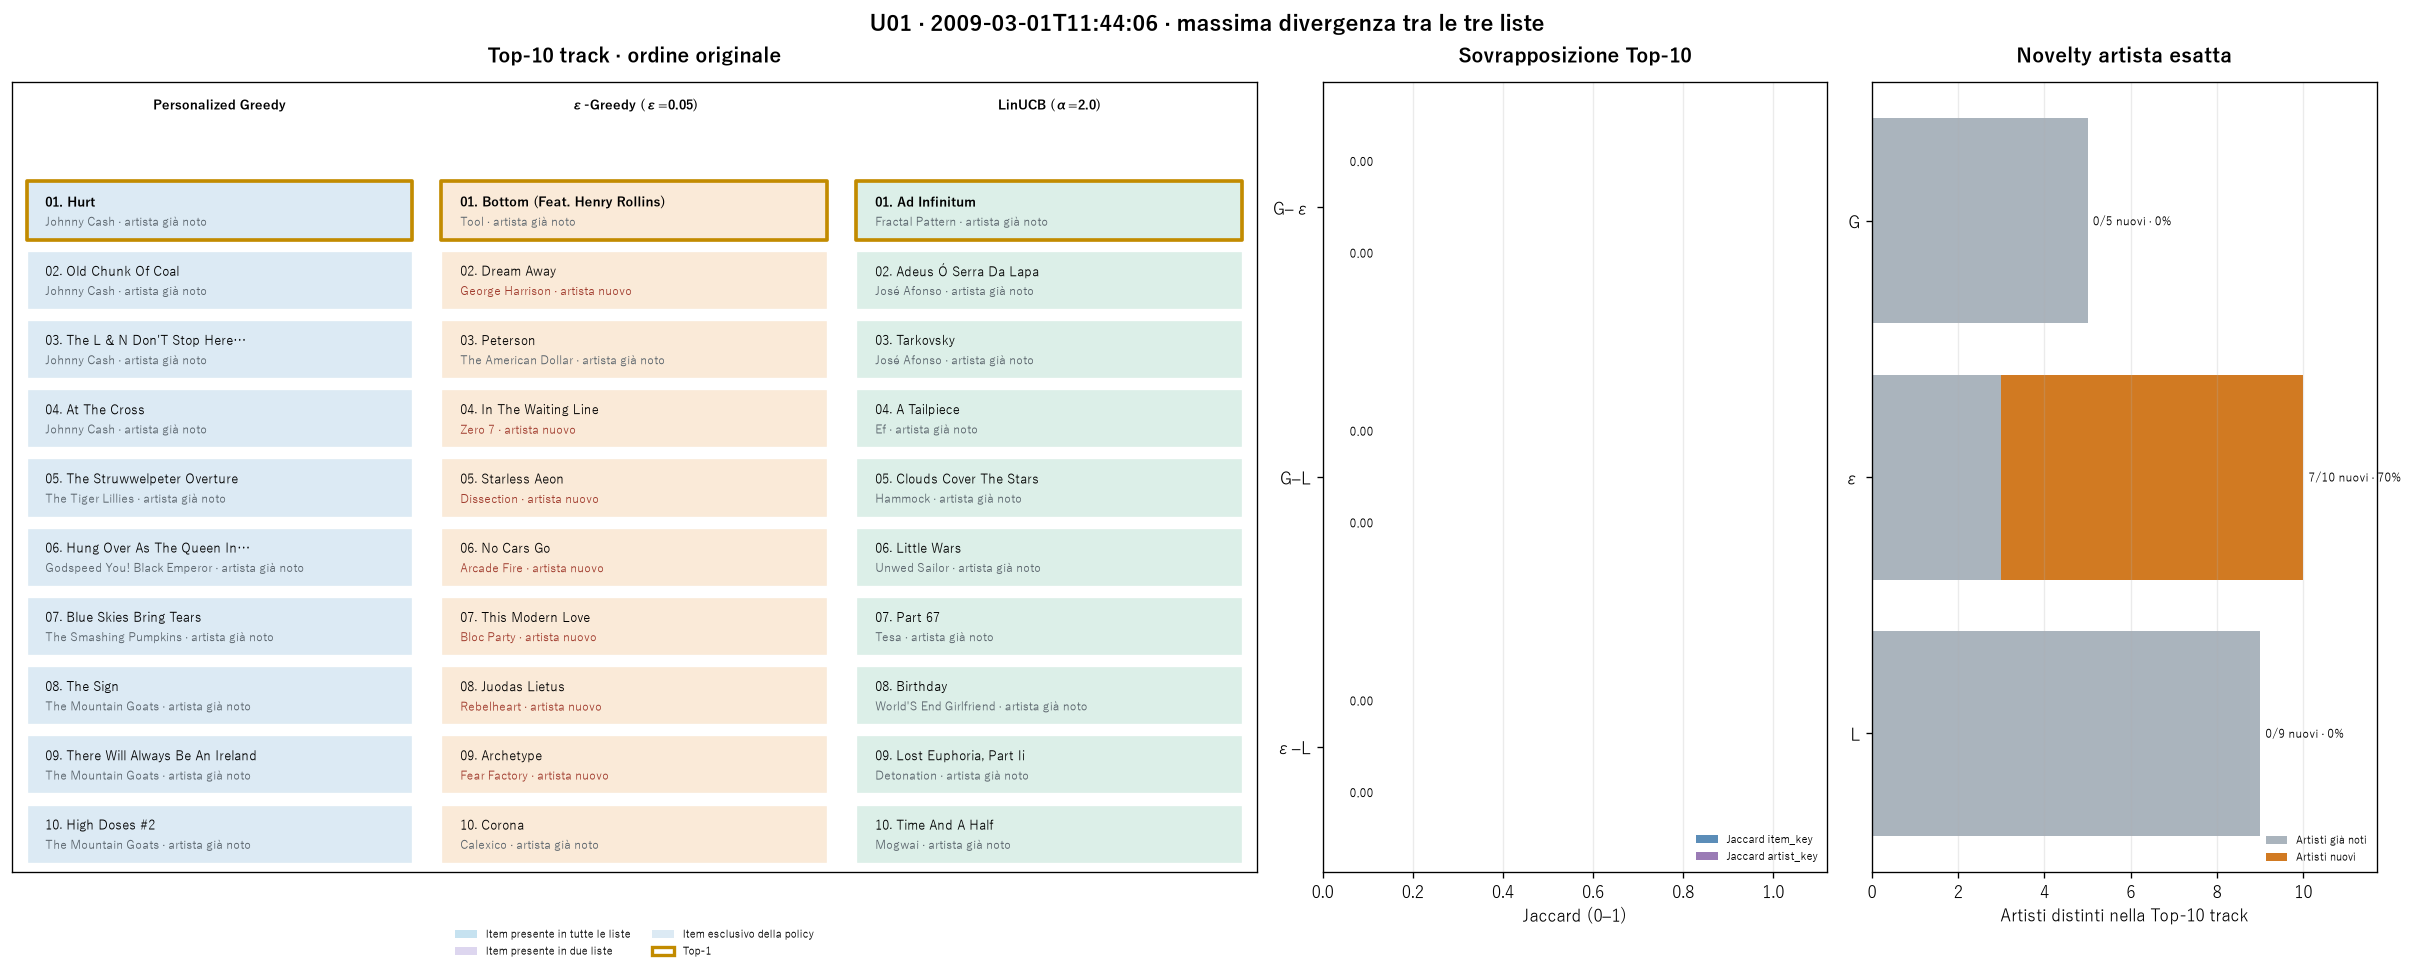

**Composizione:** 0 track comuni a tutte e tre le policy; Personalized Greedy: 10 esclusive; ε-Greedy (ε=0.05): 10 esclusive; LinUCB (α=2.0): 10 esclusive. L’overlap del grafico è calcolato separatamente su item_key e artist_key.

Nessuna track è comune alle tre Top-10.

Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,Johnny Cash,3.496508,32
ε-Greedy (ε=0.05),7,George Harrison; Zero 7; Dissection; Arcade Fire; Bloc Party; Rebelheart; Fear Factory,Tool,2.564949,12
LinUCB (α=2.0),0,Nessuno,Fractal Pattern,0.000000,0


**Nota di lettura.** Le barre Novelty artista contano `artist_key` distinti, mantenendo la prima occorrenza e usando i flag pre-decisione verificati. La track novelty non è disegnata perché la storia esatta degli `item_key` non è persistita. Reward Top-1 (proxy offline): Personalized Greedy 3.497; ε-Greedy (ε=0.05) 2.565; LinUCB (α=2.0) 0.000. Questi cinque casi sono esempi qualitativi e non dimostrano un effetto generale o causale.

### Esempio 2 · U02 · 2009-03-14T06:32:40

Selezione già congelata: **massima concordanza tra le tre liste**, strato temporale 2/5. La divergenza artist-level salvata è 0.000.

Policy,Rango,Brano (Last.fm),Artista (Last.fm),Track ID sorgente,Artist ID sorgente,Artista nuovo a t
Personalized Greedy,1,The Hands That Built America (The Edit +2.5 Varispeed),U2,006bbae4-b842-43f4-9334-e4e96e54f476,a3cb23fc-acd3-4ce0-8f36-1e5aa6a18432,No
Personalized Greedy,2,Shadow Of Your Love (Live),Guns N' Roses,005248b3-48d8-49af-93a9-cc79fe1dd7e5,eeb1195b-f213-4ce1-b28c-8565211f8e43,No
Personalized Greedy,3,November Rain (Guitar),Guns N' Roses,00bb91a7-290c-48a4-9c01-9af79579ff50,eeb1195b-f213-4ce1-b28c-8565211f8e43,No
Personalized Greedy,4,You Really Gotta Hold On Me,The Beatles,006c3e5c-5ca8-452a-9a20-6d7915ca288f,b10bbbfc-cf9e-42e0-be17-e2c3e1d2600d,No
Personalized Greedy,5,Elenor Rigby,The Beatles,00baee64-53de-4f60-87e9-a4d9bc1f7fac,b10bbbfc-cf9e-42e0-be17-e2c3e1d2600d,No
Personalized Greedy,6,So Right,Dave Matthews Band,00419e00-a9dd-4fcf-8403-c72574e6cb7e,07e748f1-075e-428d-85dc-ce3be434e906,No
Personalized Greedy,7,Scar Tissue,Red Hot Chili Peppers,eb612418-2d98-49af-9fdf-64362326632b,8bfac288-ccc5-448d-9573-c33ea2aa5c30,No
Personalized Greedy,8,Leverage Of Space,Red Hot Chili Peppers,00ac9cd2-4807-4201-a6a3-9d4ad03fadcd,8bfac288-ccc5-448d-9573-c33ea2aa5c30,No
Personalized Greedy,9,Don'T Forget Me (Live),Red Hot Chili Peppers,008ea55f-4856-4867-a603-4f62f980662a,8bfac288-ccc5-448d-9573-c33ea2aa5c30,No
Personalized Greedy,10,Poor Abbey Walsh,Marvin Gaye,0027fe1a-a2eb-44a2-9b8e-2407e2ea1a1d,afdb7919-059d-43c1-b668-ba1d265e7e42,No


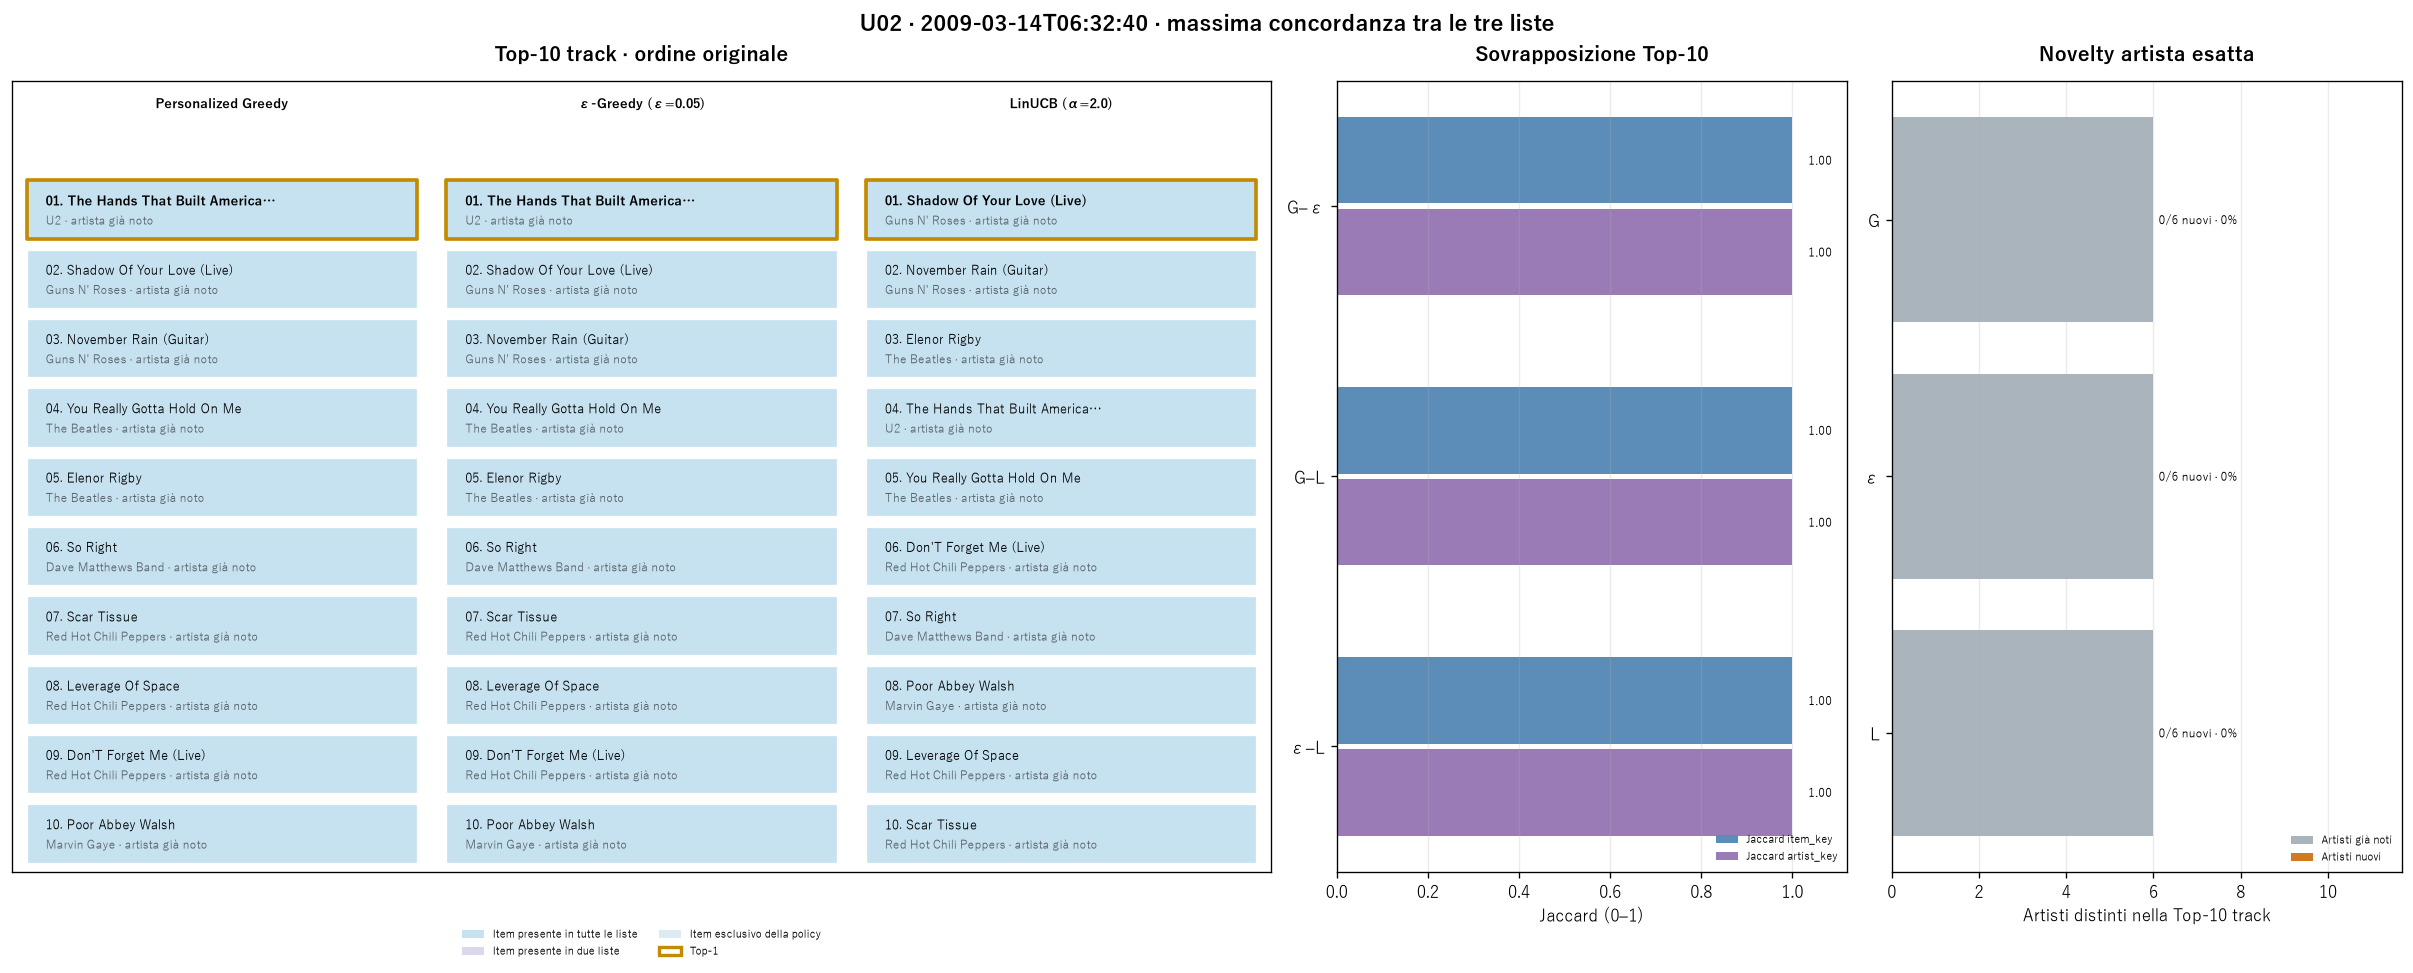

**Composizione:** 10 track comuni a tutte e tre le policy; Personalized Greedy: 0 esclusive; ε-Greedy (ε=0.05): 0 esclusive; LinUCB (α=2.0): 0 esclusive. L’overlap del grafico è calcolato separatamente su item_key e artist_key.

Brano comune,Personalized Greedy,ε-Greedy (ε=0.05),LinUCB (α=2.0)
The Hands That Built America (The Edit +2.5 Varispeed),1,1,4
Shadow Of Your Love (Live),2,2,1
November Rain (Guitar),3,3,2
You Really Gotta Hold On Me,4,4,5
Elenor Rigby,5,5,3
So Right,6,6,7
Scar Tissue,7,7,10
Leverage Of Space,8,8,9
Don'T Forget Me (Live),9,9,6
Poor Abbey Walsh,10,10,8


Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,U2,3.663562,38
ε-Greedy (ε=0.05),0,Nessuno,U2,3.663562,38
LinUCB (α=2.0),0,Nessuno,Guns N' Roses,2.890372,17


**Nota di lettura.** Le barre Novelty artista contano `artist_key` distinti, mantenendo la prima occorrenza e usando i flag pre-decisione verificati. La track novelty non è disegnata perché la storia esatta degli `item_key` non è persistita. Reward Top-1 (proxy offline): Personalized Greedy 3.664; ε-Greedy (ε=0.05) 3.664; LinUCB (α=2.0) 2.890. Questi cinque casi sono esempi qualitativi e non dimostrano un effetto generale o causale.

### Esempio 3 · U03 · 2009-03-27T10:04:41

Selezione già congelata: **divergenza mediana tra le tre liste**, strato temporale 3/5. La divergenza artist-level salvata è 0.200.

Policy,Rango,Brano (Last.fm),Artista (Last.fm),Track ID sorgente,Artist ID sorgente,Artista nuovo a t
Personalized Greedy,1,Arabesque (Vocal Version),Micatone,001e3637-7239-4ffc-a9ae-feb0b292ec59,ca30be07-e94e-4bd8-a022-1dfbc462905b,No
Personalized Greedy,2,Seven Light Years,Rjd2,0016c481-6ab5-474e-9630-4eb1df943d82,1a120ec5-35b3-4f3e-aa49-7201550d9feb,No
Personalized Greedy,3,Hora Cero,Astor Piazzolla,00328e8f-a4b4-4502-9c0f-346e864b47ba,e280268a-a5ab-4bb0-be4d-ec470ca59131,No
Personalized Greedy,4,The Lazy Sunbathers,Morrissey,00175d60-765f-4663-8d77-60024f489c16,013fa897-86db-41d3-8e9f-386c8a34f4e6,No
Personalized Greedy,5,Sister I'M A Poet (Live),Morrissey,0026dfa1-5ef3-46fd-9f15-b9ca962eb36e,013fa897-86db-41d3-8e9f-386c8a34f4e6,No
Personalized Greedy,6,Midnight Melodic (Chase The Blues),Terranova,0038190f-214d-459c-98fb-d90dcae1357e,00950dec-8f3a-4a17-9717-e7872a954d8b,No
Personalized Greedy,7,Thanks For The Memory,Frank Sinatra,001438be-cfe2-4415-9f04-8cdae78ec6b1,197450cd-0124-4164-b723-3c22dd16494d,No
Personalized Greedy,8,He'S Got The Whole World In His Hand,Nina Simone,0017b010-f89a-481b-b067-acd7757232a7,2944824d-4c26-476f-a981-be849081942f,No
Personalized Greedy,9,Evil,Interpol,6c450822-41ca-444e-8be5-10ee5a9ea53a,b23e8a63-8f47-4882-b55b-df2c92ef400e,No
Personalized Greedy,10,Slow Hands,Interpol,d0eb0d3c-cf52-4e23-8b6d-2fd03f7c8f70,b23e8a63-8f47-4882-b55b-df2c92ef400e,No


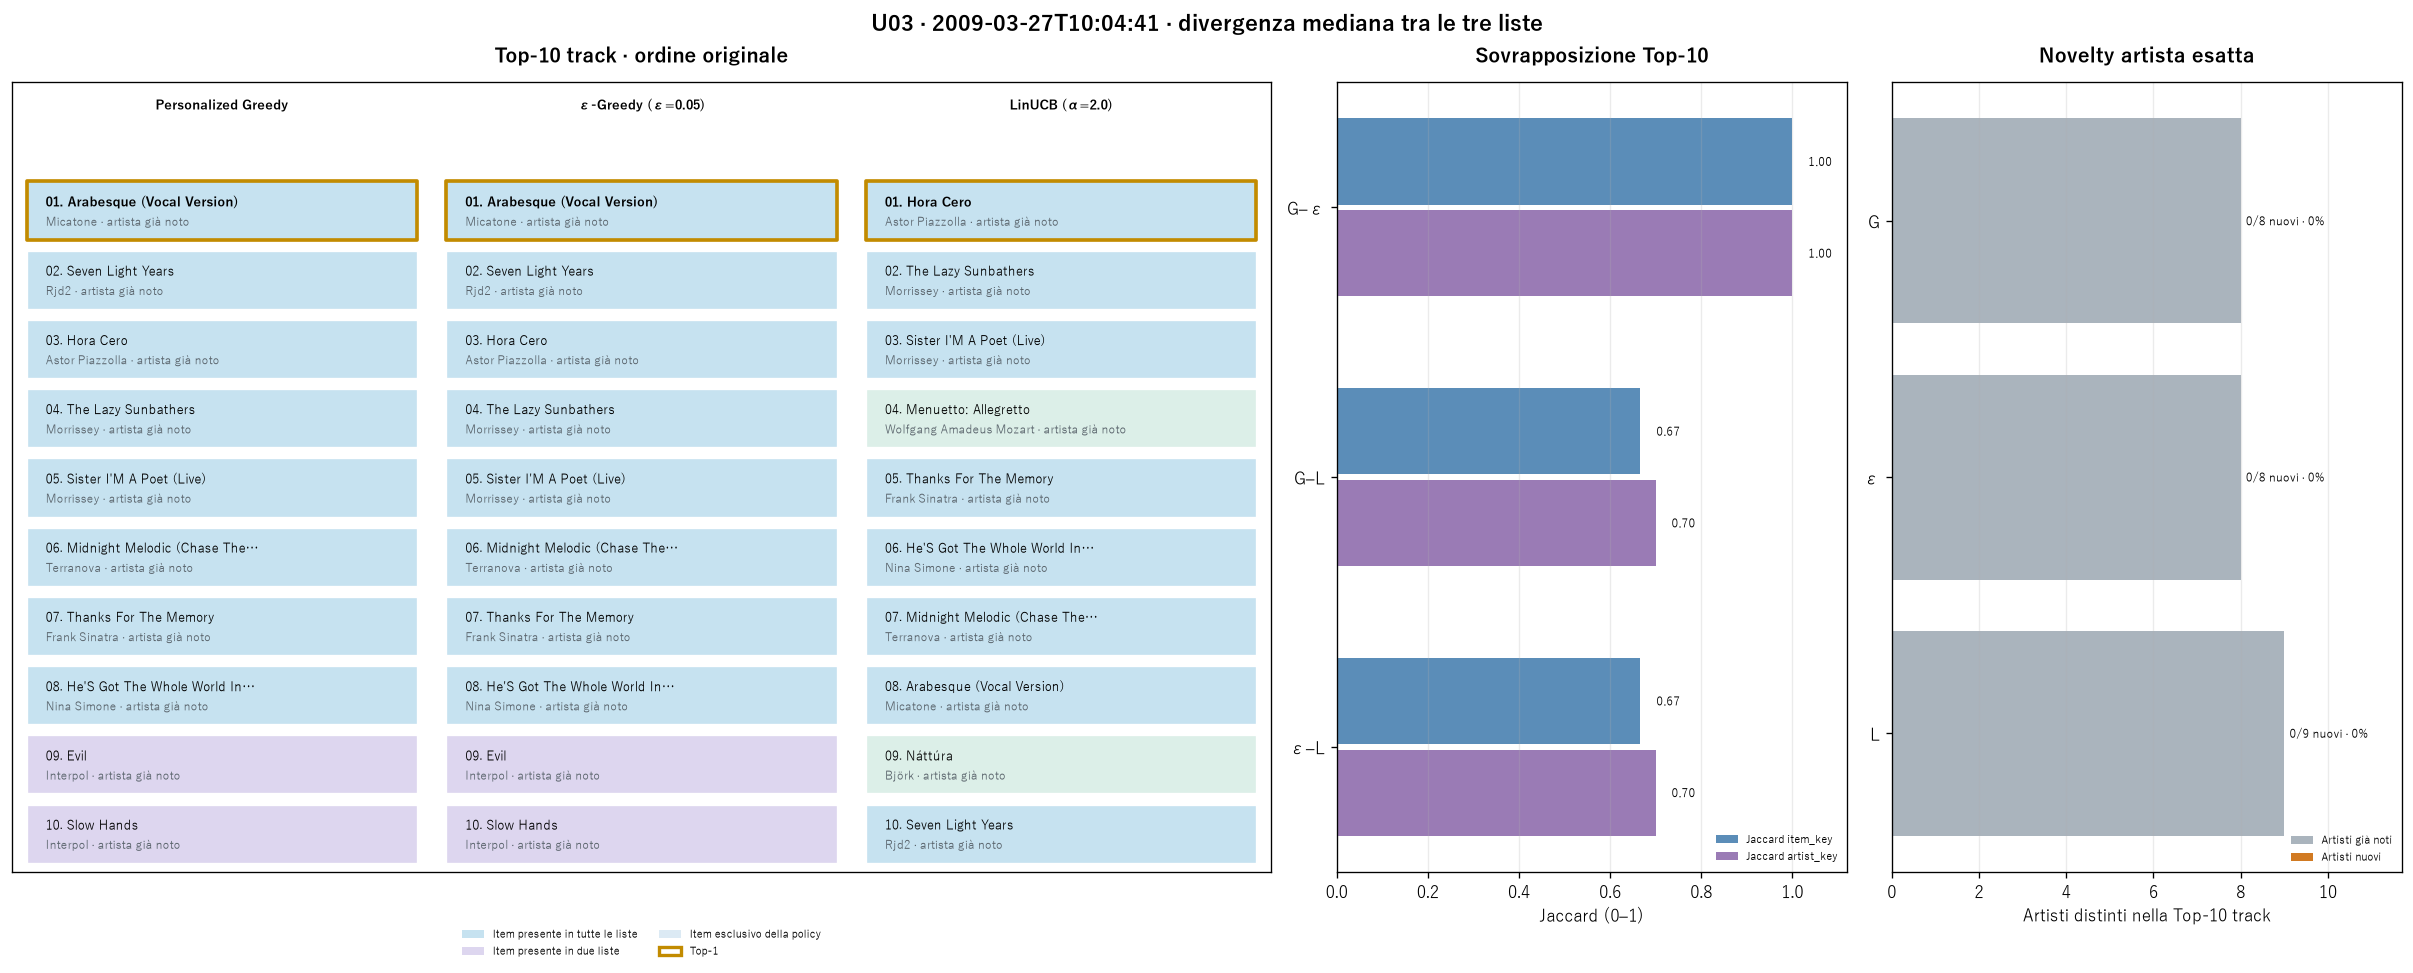

**Composizione:** 8 track comuni a tutte e tre le policy; Personalized Greedy: 0 esclusive; ε-Greedy (ε=0.05): 0 esclusive; LinUCB (α=2.0): 2 esclusive. L’overlap del grafico è calcolato separatamente su item_key e artist_key.

Brano comune,Personalized Greedy,ε-Greedy (ε=0.05),LinUCB (α=2.0)
Arabesque (Vocal Version),1,1,8
Seven Light Years,2,2,10
Hora Cero,3,3,1
The Lazy Sunbathers,4,4,2
Sister I'M A Poet (Live),5,5,3
Midnight Melodic (Chase The Blues),6,6,7
Thanks For The Memory,7,7,5
He'S Got The Whole World In His Hand,8,8,6


Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,Micatone,0.000000,0
ε-Greedy (ε=0.05),0,Nessuno,Micatone,0.000000,0
LinUCB (α=2.0),0,Nessuno,Astor Piazzolla,3.526361,33


**Nota di lettura.** Le barre Novelty artista contano `artist_key` distinti, mantenendo la prima occorrenza e usando i flag pre-decisione verificati. La track novelty non è disegnata perché la storia esatta degli `item_key` non è persistita. Reward Top-1 (proxy offline): Personalized Greedy 0.000; ε-Greedy (ε=0.05) 0.000; LinUCB (α=2.0) 3.526. Questi cinque casi sono esempi qualitativi e non dimostrano un effetto generale o causale.

### Esempio 4 · U04 · 2009-04-09T15:08:15

Selezione già congelata: **massima divergenza Personalized Greedy–LinUCB**, strato temporale 4/5. La divergenza artist-level salvata è 0.667.

Policy,Rango,Brano (Last.fm),Artista (Last.fm),Track ID sorgente,Artist ID sorgente,Artista nuovo a t
Personalized Greedy,1,Charmer,Kings Of Leon,006f6df6-8b50-4aa5-ab61-0009b81dc1eb,6ffb8ea9-2370-44d8-b678-e9237bbd347b,No
Personalized Greedy,2,Time To Pretend,Mgmt,24436eea-e79f-4592-b7f8-3e9bfe01f483,c485632c-b784-4ee9-8ea1-c5fb365681fc,No
Personalized Greedy,3,Kids,Mgmt,c741a7ef-dd33-4c79-a4d4-8745d9675620,c485632c-b784-4ee9-8ea1-c5fb365681fc,No
Personalized Greedy,4,Electric Feel,Mgmt,987a88ef-6f47-479c-a0ad-1a17aa85e8ed,c485632c-b784-4ee9-8ea1-c5fb365681fc,No
Personalized Greedy,5,"Like A Prayer (7"" Remix Edit)",Madonna,0065e7f8-2976-42ec-b879-d44e835e9cbc,79239441-bfd5-4981-a70c-55c3f15c1287,No
Personalized Greedy,6,Hung Up (Bill Hamel Remix),Madonna,010b8f63-f747-442f-9c58-cf321085b981,79239441-bfd5-4981-a70c-55c3f15c1287,No
Personalized Greedy,7,Jump (Axwell Remix),Madonna,0024c359-f9b5-4d72-a35f-355efa52cdfa,79239441-bfd5-4981-a70c-55c3f15c1287,No
Personalized Greedy,8,Hung Up (Sdp'S Extended Vocal),Madonna,01159eb5-7ded-46a3-96d1-49be1562763f,79239441-bfd5-4981-a70c-55c3f15c1287,No
Personalized Greedy,9,The Scientist,Coldplay,a478f801-521b-40e7-8bb4-5faeffb1f3e4,cc197bad-dc9c-440d-a5b5-d52ba2e14234,No
Personalized Greedy,10,Viva La Vida,Coldplay,6cbbb97d-2180-4ba9-97a8-6158b6332bb4,cc197bad-dc9c-440d-a5b5-d52ba2e14234,No


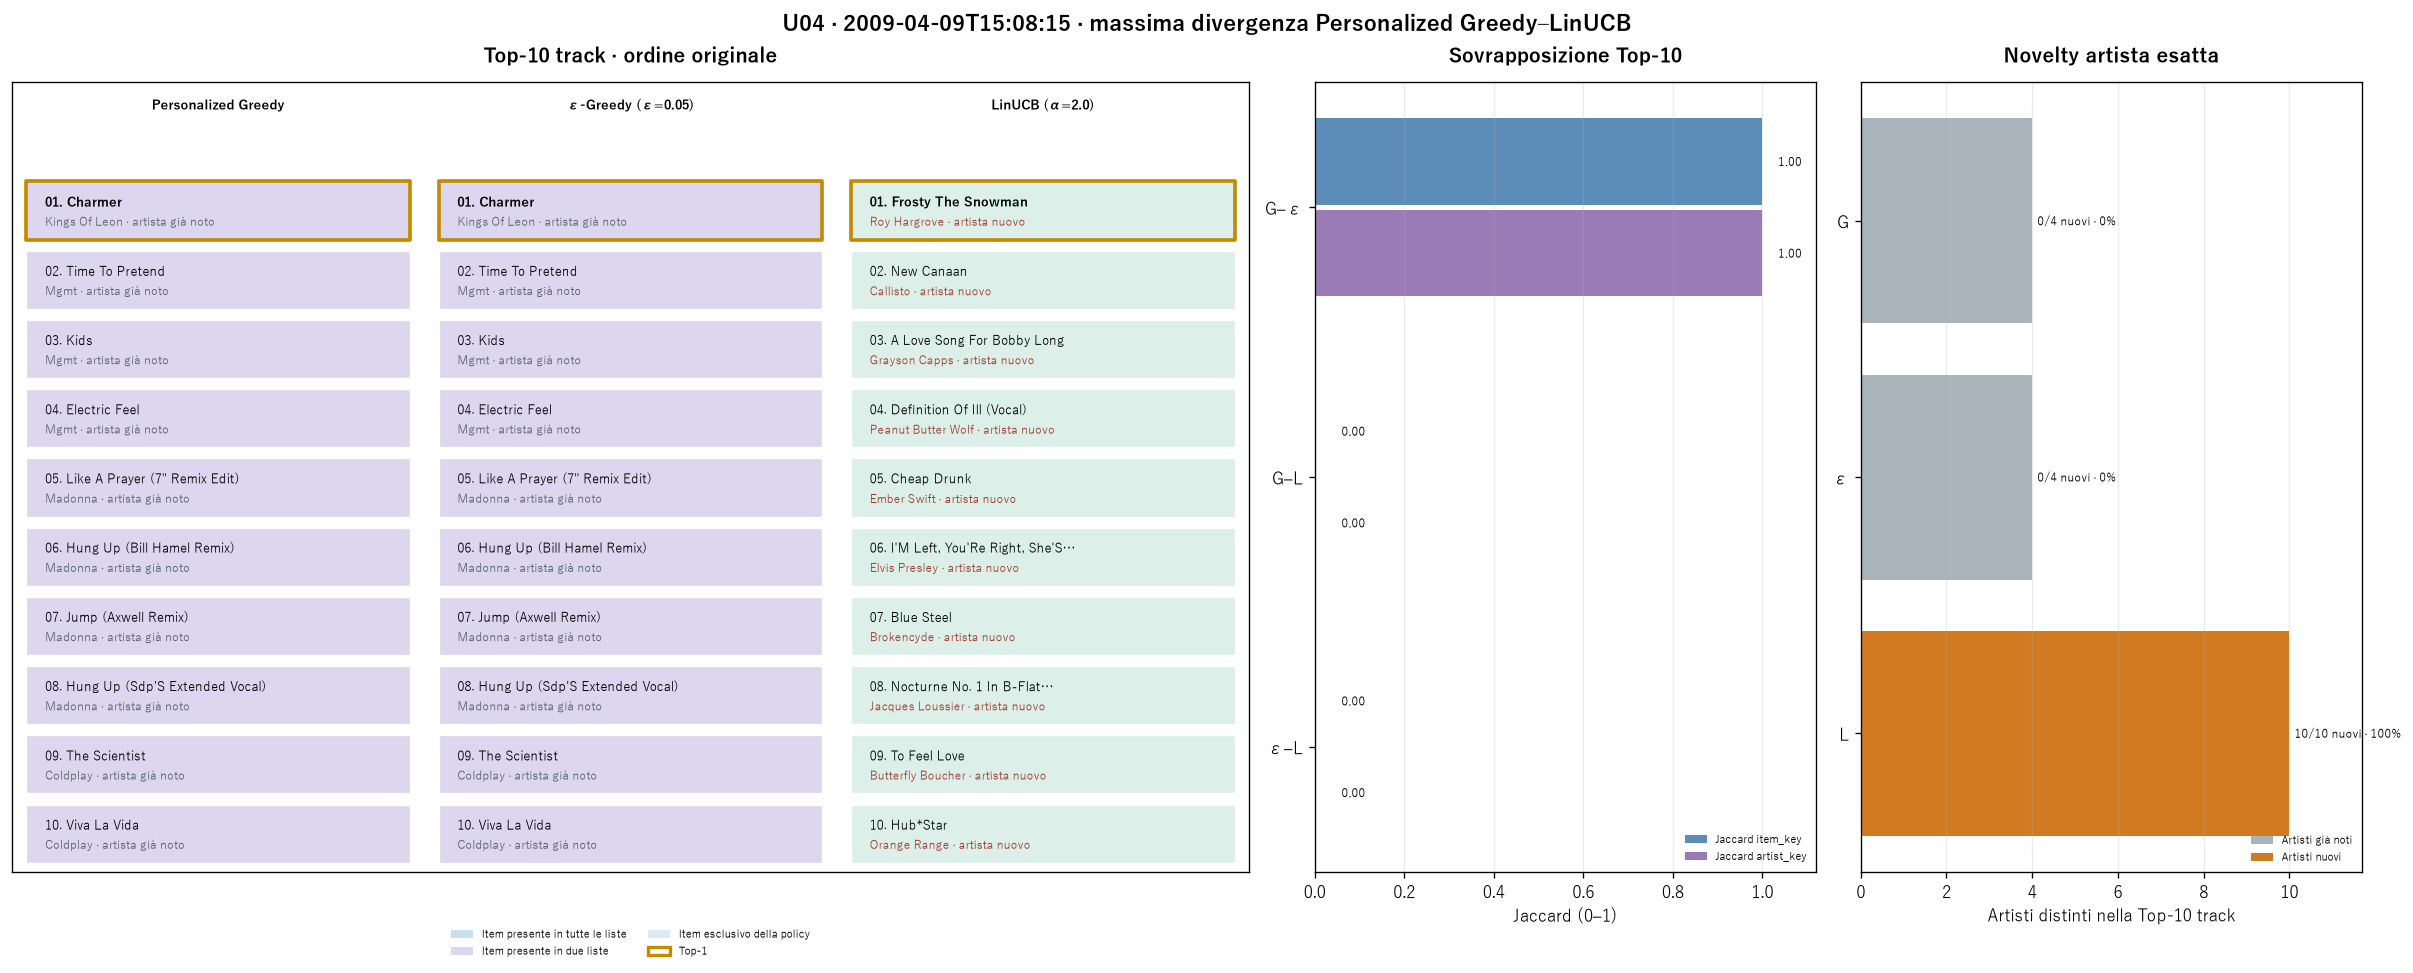

**Composizione:** 0 track comuni a tutte e tre le policy; Personalized Greedy: 0 esclusive; ε-Greedy (ε=0.05): 0 esclusive; LinUCB (α=2.0): 10 esclusive. L’overlap del grafico è calcolato separatamente su item_key e artist_key.

Nessuna track è comune alle tre Top-10.

Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,Kings Of Leon,0.693147,1
ε-Greedy (ε=0.05),0,Nessuno,Kings Of Leon,0.693147,1
LinUCB (α=2.0),10,Roy Hargrove; Callisto; Grayson Capps; Peanut Butter Wolf; Ember Swift; Elvis Presley; Brokencyde; Jacques Loussier; Butterfly Boucher; Orange Range,Roy Hargrove,0.000000,0


**Nota di lettura.** Le barre Novelty artista contano `artist_key` distinti, mantenendo la prima occorrenza e usando i flag pre-decisione verificati. La track novelty non è disegnata perché la storia esatta degli `item_key` non è persistita. Reward Top-1 (proxy offline): Personalized Greedy 0.693; ε-Greedy (ε=0.05) 0.693; LinUCB (α=2.0) 0.000. Questi cinque casi sono esempi qualitativi e non dimostrano un effetto generale o causale.

### Esempio 5 · U05 · 2009-04-22T19:25:47

Selezione già congelata: **massima divergenza Personalized Greedy–ε-Greedy**, strato temporale 5/5. La divergenza artist-level salvata è 0.833.

Policy,Rango,Brano (Last.fm),Artista (Last.fm),Track ID sorgente,Artist ID sorgente,Artista nuovo a t
Personalized Greedy,1,Afraid,Patrick Wolf,0053c2a0-876b-49e7-b68b-f2cc750cc42b,4ac4e32b-bd18-402e-adad-ae00e72f8d85,No
Personalized Greedy,2,Karma Police,Radiohead,9e2ad5bc-c6f9-40d2-a36f-3122ee2072a3,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,3,All I Need,Radiohead,72c6b4d3-71a8-4c70-bf50-da11c0149089,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,4,Creep,Radiohead,43156f35-eead-47a8-9ffe-6fdcd915f031,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,5,15 Step,Radiohead,e5be3063-0f68-4c28-8a4e-d19a354b0872,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,6,Nude,Radiohead,8fa2de7e-49e0-4201-87ae-d9f2bab81730,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,7,Reckoner,Radiohead,76ccedbc-ce16-4c2b-8c05-fe2749c219a9,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,8,Paranoid Android,Radiohead,49888c84-b4f7-491e-a93c-40c6c0393c19,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,9,Jigsaw Falling Into Place,Radiohead,31600df4-e6dd-48ca-9f6b-8804027d8d6e,a74b1b7f-71a5-4011-9441-d0b5e4122711,No
Personalized Greedy,10,Fake Plastic Trees,Radiohead,9f17eb0c-9b6a-471b-af27-649270b576de,a74b1b7f-71a5-4011-9441-d0b5e4122711,No


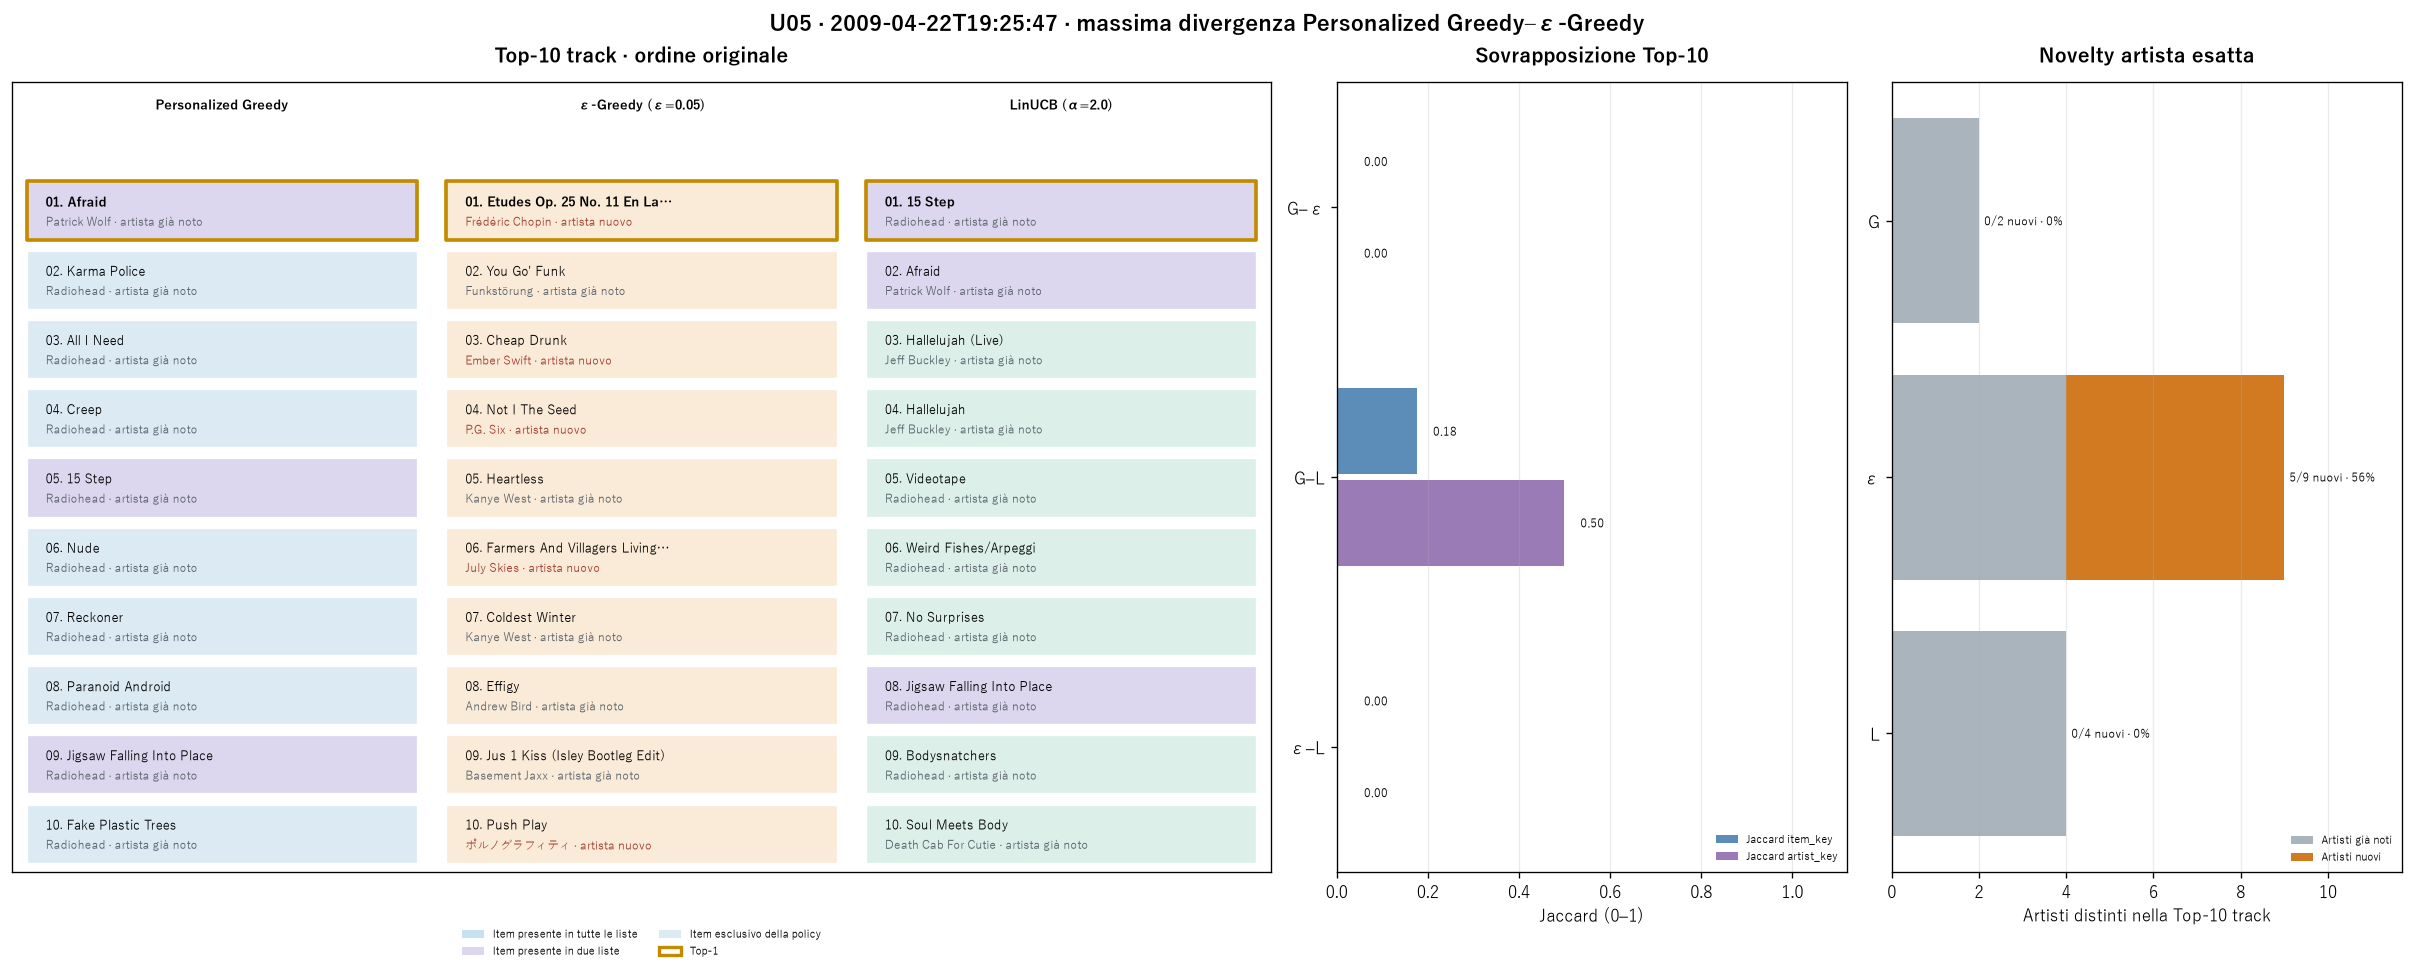

**Composizione:** 0 track comuni a tutte e tre le policy; Personalized Greedy: 7 esclusive; ε-Greedy (ε=0.05): 10 esclusive; LinUCB (α=2.0): 7 esclusive. L’overlap del grafico è calcolato separatamente su item_key e artist_key.

Nessuna track è comune alle tre Top-10.

Policy,Nuovi artisti distinti in Top-10,Artisti nuovi (nomi catalogo),Artista Top-1,Reward Top-1 (proxy offline),"Ascolti futuri dello stesso artista in (t,t+7d]"
Personalized Greedy,0,Nessuno,Patrick Wolf,0.000000,0
ε-Greedy (ε=0.05),5,Frédéric Chopin; Ember Swift; P.G. Six; July Skies; ポルノグラフィティ,Frédéric Chopin,0.000000,0
LinUCB (α=2.0),0,Nessuno,Radiohead,3.663562,38


**Nota di lettura.** Le barre Novelty artista contano `artist_key` distinti, mantenendo la prima occorrenza e usando i flag pre-decisione verificati. La track novelty non è disegnata perché la storia esatta degli `item_key` non è persistita. Reward Top-1 (proxy offline): Personalized Greedy 0.000; ε-Greedy (ε=0.05) 0.000; LinUCB (α=2.0) 3.664. Questi cinque casi sono esempi qualitativi e non dimostrano un effetto generale o causale.

In [9]:
from IPython.display import Markdown, display
from matplotlib.patches import Patch, Rectangle
import matplotlib.pyplot as plt
import textwrap

plt.rcParams["font.family"] = ["Yu Gothic", "DejaVu Sans"]
QUAL_POLICY_COLORS = {"greedy": "#2878B5", "epsilon_greedy": "#D17A22", "linucb": "#3A8C78"}
QUAL_SHARED_COLOR = "#c6e2f0"
QUAL_PAIR_COLOR = "#ddd6ef"

def _jaccard(left, right):
    left, right = set(left), set(right)
    return len(left & right) / len(left | right) if left or right else 1.0

def _distinct_artist_novelty(recommendations):
    flags = {}
    for row in recommendations:
        key = row["artist_key"]
        novel = row["artist_is_new_before_t"]
        if key in flags:
            assert flags[key] == novel, "Un artista ha flag pre-decisione incoerenti"
        else:
            flags[key] = novel
    novel_count = sum(flags.values())
    return novel_count, len(flags) - novel_count, len(flags)

def _item_fill(members):
    if len(members) == 3:
        return QUAL_SHARED_COLOR
    if len(members) == 2:
        return QUAL_PAIR_COLOR
    policy = next(iter(members))
    return {"greedy": "#dceaf4", "epsilon_greedy": "#faead8", "linucb": "#dcefe8"}[policy]

def _render_example_figure(example):
    policy_items = {
        p: set(example["policies"][p]["top_k_item_keys"][:10])
        for p in QUAL_POLICY_ORDER
    }
    policy_artists = {
        p: set(example["policies"][p]["top_k_artist_keys"][:10])
        for p in QUAL_POLICY_ORDER
    }
    fig, axes = plt.subplots(
        1, 3, figsize=(20, 8), constrained_layout=True,
        gridspec_kw={"width_ratios": [3.7, 1.5, 1.5]},
    )
    rank_ax, overlap_ax, novelty_ax = axes

    rank_ax.set_xlim(0, 3)
    rank_ax.set_ylim(-1.35, 10.05)
    rank_ax.invert_yaxis()
    rank_ax.set_xticks([])
    rank_ax.set_yticks([])
    rank_ax.set_title("Top-10 track · ordine originale", fontweight="bold", pad=12)
    for column, policy in enumerate(QUAL_POLICY_ORDER):
        rank_ax.text(column + 0.5, -1.03, QUAL_LABEL[policy], ha="center", va="center", fontsize=8, fontweight="bold")
        rows = example["policies"][policy]["recommendations"]
        for row in rows:
            rank = int(row["rank"])
            y = rank - 0.5
            item_members = {p for p in QUAL_POLICY_ORDER if row["item_key"] in policy_items[p]}
            edge = "#c28b00" if rank == 1 else "white"
            linewidth = 2.2 if rank == 1 else 0.8
            rank_ax.add_patch(Rectangle(
                (column + 0.035, y - 0.42), 0.93, 0.84,
                facecolor=_item_fill(item_members), edgecolor=edge,
                linewidth=linewidth, joinstyle="round",
            ))
            title = textwrap.shorten(row["track_title"], width=31, placeholder="…")
            artist = textwrap.shorten(row["artist_name"], width=29, placeholder="…")
            rank_ax.text(column + 0.08, y - 0.13, f"{rank:02d}. {title}", ha="left", va="center", fontsize=8.0, fontweight="bold" if rank == 1 else "normal")
            status = "artista nuovo" if row["artist_is_new_before_t"] else "artista già noto"
            rank_ax.text(column + 0.08, y + 0.16, f"{artist} · {status}", ha="left", va="center", fontsize=7.0, color="#a13c2e" if row["artist_is_new_before_t"] else "#59636b")
    rank_ax.legend(handles=[
        Patch(facecolor=QUAL_SHARED_COLOR, label="Item presente in tutte le liste"),
        Patch(facecolor=QUAL_PAIR_COLOR, label="Item presente in due liste"),
        Patch(facecolor="#dceaf4", label="Item esclusivo della policy"),
        Patch(facecolor="white", edgecolor="#c28b00", linewidth=2, label="Top-1"),
    ], loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=6.5, frameon=False)

    pairs = [
        ("G–ε", "greedy", "epsilon_greedy"),
        ("G–L", "greedy", "linucb"),
        ("ε–L", "epsilon_greedy", "linucb"),
    ]
    y_positions = list(range(len(pairs)))
    track_values = [_jaccard(policy_items[a], policy_items[b]) for _, a, b in pairs]
    artist_values = [_jaccard(policy_artists[a], policy_artists[b]) for _, a, b in pairs]
    overlap_ax.barh([y - 0.17 for y in y_positions], track_values, height=0.32, color="#5b8db8", label="Jaccard item_key")
    overlap_ax.barh([y + 0.17 for y in y_positions], artist_values, height=0.32, color="#9a7bb5", label="Jaccard artist_key")
    for ys, values in (([y - 0.17 for y in y_positions], track_values), ([y + 0.17 for y in y_positions], artist_values)):
        for y, value in zip(ys, values):
            overlap_ax.text(max(value + 0.035, 0.06), y, f"{value:.2f}", va="center", fontsize=7)
    overlap_ax.set_yticks(y_positions, [p[0] for p in pairs])
    overlap_ax.invert_yaxis()
    overlap_ax.set_xlim(0, 1.12)
    overlap_ax.set_xlabel("Jaccard (0–1)")
    overlap_ax.set_title("Sovrapposizione Top-10", fontweight="bold", pad=12)
    overlap_ax.legend(loc="lower right", fontsize=6.5, frameon=False)
    overlap_ax.grid(axis="x", alpha=0.25)

    novelty_rows = []
    for policy in QUAL_POLICY_ORDER:
        new_count, known_count, distinct_count = _distinct_artist_novelty(example["policies"][policy]["recommendations"])
        novelty_rows.append((policy, new_count, known_count, distinct_count))
    novelty_y = list(range(3))
    known_counts = [row[2] for row in novelty_rows]
    new_counts = [row[1] for row in novelty_rows]
    novelty_ax.barh(novelty_y, known_counts, color="#aab4bd", label="Artisti già noti")
    novelty_ax.barh(novelty_y, new_counts, left=known_counts, color="#d17a22", label="Artisti nuovi")
    for y, (_, new_count, known_count, total) in zip(novelty_y, novelty_rows):
        pct = 100 * new_count / total if total else 0.0
        novelty_ax.text(total + 0.12, y, f"{new_count}/{total} nuovi · {pct:.0f}%", va="center", fontsize=7)
    novelty_ax.set_yticks(novelty_y, [QUAL_POLICY_SHORT[row[0]] for row in novelty_rows])
    novelty_ax.invert_yaxis()
    novelty_ax.set_xlim(0, 11.7)
    novelty_ax.set_xticks(range(0, 11, 2))
    novelty_ax.set_xlabel("Artisti distinti nella Top-10 track")
    novelty_ax.set_title("Novelty artista esatta", fontweight="bold", pad=12)
    novelty_ax.legend(loc="lower right", fontsize=6.5, frameon=False)
    novelty_ax.grid(axis="x", alpha=0.25)

    fig.suptitle(
        f"{example['alias']} · {example['decision_time']} · {example['criterion']}",
        fontsize=13, fontweight="bold",
    )
    display(fig)
    plt.close(fig)

for example in QUAL_EXAMPLES:
    display(Markdown(
        f"### Esempio {example['index']} · {example['alias']} · {example['decision_time']}\n\n"
        f"Selezione già congelata: **{example['criterion']}**, strato temporale "
        f"{example['time_stratum']}/5. La divergenza artist-level salvata è "
        f"{example['overall_divergence']:.3f}."
    ))
    rows = []
    for policy in QUAL_POLICY_ORDER:
        record = example["policies"][policy]
        for item in record["recommendations"]:
            rows.append({
                "Policy": QUAL_LABEL[policy],
                "Rango": item["rank"],
                "Brano (Last.fm)": item["track_title"],
                "Artista (Last.fm)": item["artist_name"],
                "Track ID sorgente": item["source_track_id"] or "ID assente; fallback per titolo",
                "Artist ID sorgente": item["source_artist_id"] or "ID assente; fallback per nome",
                "Artista nuovo a t": "Sì" if item["artist_is_new_before_t"] else "No",
            })
    display(pd.DataFrame(rows))
    _render_example_figure(example)

    track_lists = {p: set(example["policies"][p]["top_k_item_keys"][:10]) for p in QUAL_POLICY_ORDER}
    common_items = set.intersection(*(track_lists[p] for p in QUAL_POLICY_ORDER))
    exclusive = {
        p: len(track_lists[p] - set.union(*(track_lists[q] for q in QUAL_POLICY_ORDER if q != p)))
        for p in QUAL_POLICY_ORDER
    }
    common_rows = []
    for item_key in example["policies"]["greedy"]["top_k_item_keys"][:10]:
        if item_key in common_items:
            meta = QUAL_CATALOG[item_key]
            common_rows.append({
                "Brano comune": meta["track_names"][0],
                **{
                    QUAL_LABEL[p]: example["policies"][p]["top_k_item_keys"].index(item_key) + 1
                    for p in QUAL_POLICY_ORDER
                },
            })
    display(Markdown(
        f"**Composizione:** {len(common_items)} track comuni a tutte e tre le policy; "
        + "; ".join(f"{QUAL_LABEL[p]}: {exclusive[p]} esclusive" for p in QUAL_POLICY_ORDER)
        + ". L’overlap del grafico è calcolato separatamente su item_key e artist_key."
    ))
    if common_rows:
        display(pd.DataFrame(common_rows))
    else:
        display(Markdown("Nessuna track è comune alle tre Top-10."))

    reward_rows = []
    new_counts = {}
    for policy in QUAL_POLICY_ORDER:
        record = example["policies"][policy]
        meta = QUAL_CATALOG[record["selected_item_key"]]
        new_artist_names = []
        seen_artists = set()
        for item in record["recommendations"]:
            if item["artist_key"] in seen_artists:
                continue
            seen_artists.add(item["artist_key"])
            if item["artist_is_new_before_t"]:
                new_artist_names.append(item["artist_name"])
        new_count, _, _ = _distinct_artist_novelty(record["recommendations"])
        new_counts[policy] = new_count
        reward_rows.append({
            "Policy": QUAL_LABEL[policy],
            "Nuovi artisti distinti in Top-10": new_count,
            "Artisti nuovi (nomi catalogo)": "; ".join(dict.fromkeys(new_artist_names)) or "Nessuno",
            "Artista Top-1": meta["artist_names"][0],
            "Reward Top-1 (proxy offline)": record["reward"],
            "Ascolti futuri dello stesso artista in (t,t+7d]": QUAL_FUTURE_COUNTS[(example["user_id"], example["decision_time"])][record["selected_artist"]],
        })
    display(pd.DataFrame(reward_rows).round(6))
    reward_text = "; ".join(f"{QUAL_LABEL[p]} {example['policies'][p]['reward']:.3f}" for p in QUAL_POLICY_ORDER)
    display(Markdown(
        "**Nota di lettura.** Le barre Novelty artista contano `artist_key` distinti, "
        "mantenendo la prima occorrenza e usando i flag pre-decisione verificati. "
        "La track novelty non è disegnata perché la storia esatta degli `item_key` "
        "non è persistita. Reward Top-1 (proxy offline): " + reward_text + ". "
        "Questi cinque casi sono esempi qualitativi e non dimostrano un effetto generale o causale."
    ))

print("Esempi qualitativi renderizzati dalla cache:", len(QUAL_EXAMPLES), "| utenti distinti:", len({x['user_id'] for x in QUAL_EXAMPLES}))

## 7. Conclusioni e limiti

- Il test è un confronto descrittivo delle cinque configurazioni fissate dalla validation; non modifica il modello selezionato.
- La reward usa play futuri dello stesso utente per l'artista Top-1 nella finestra `(t, t+7 giorni]`. Mancando log di esposizione, non è una misura causale e non consente IPS/SNIPS.
- I decision point sono sequenziali e dipendenti nel tempo. Gli aggregati globali non consentono inferenza per utente; i JSONL contengono decision record, ma un bootstrap corretto richiede ricostruire metriche appaiate per utente preservando l'ordine temporale. Non vengono dichiarate significatività o intervalli di confidenza in questo notebook.
- Le metriche di novelty, diversità e coverage descrivono la varietà delle raccomandazioni e non dimostrano che i contenuti siano stati effettivamente ascoltati o apprezzati.

Le conclusioni sostenibili restano limitate a queste policy, al periodo held-out e alla simulazione offline adottata.

In [10]:
print(f'Configurazioni held-out: {len(test)}/5; candidate depth N={test.candidate_pool_depth.unique().tolist()}')
print('Ordinamento NDCG@10:', ' > '.join(LABEL[p] for p in test.sort_values('ndcg@10',ascending=False).policy))
print('La selezione resta quella validation del manifesto; nessun tuning sul test è stato eseguito.')

Configurazioni held-out: 5/5; candidate depth N=[100]
Ordinamento NDCG@10: Personalized Greedy > LinUCB > ε-Greedy > Random > Global Popularity
La selezione resta quella validation del manifesto; nessun tuning sul test è stato eseguito.
